## Projeto 7 - Segmentando Classes Alimentares - Alimentação

### Definino o Objetivo do Projeto
<p> Solicitação do Cliente: Separar os clientes que são Veganos, Vegetarianos e Sem Restrição
<br> Para esse objetivo, utilizaremos um algoritmo de clusterização (grupos)


### Atividades Adicionais (Gerando Valor com Dados)
1 - Alimento mais consumido por estado
<br>2 - Total de produtos consumidos por estado
<br>3 - Os 3 produtos mais consumidos por estado
<br>4 - Quantidade de Veganos, Vegetarianos e Sem Restrição por Estado
<br>5 - Percentual de Veganos, Vegetarianos e Sem Restrição por Estado
<br>6 - Estado com maior quantidade e percentual correspondente de Veganos, Vegetarianos e Sem Restrição
<br>7 - Relação dos produtos consumidos e sua respectiva quantidade    


<p>Ao final, exportar a planilha com todos esses dados para nosso cliente

In [1]:
# Instalando o pacote XlsxWriter
!pip install XlsxWriter

In [2]:
!python.exe -m pip install --upgrade pip

In [3]:
# =====================================================================
# IMPORTAÇÕES DE BIBLIOTECAS
# =====================================================================

# Biblioteca para manipulação e análise de dados tabulares (DataFrames e Series)
import pandas as pd
# Biblioteca para operações numéricas e manipulação de arrays
import numpy as np

# Biblioteca para criação de gráficos e visualizações
import matplotlib.pyplot as plt

# Biblioteca para visualizações estatísticas mais sofisticadas
import seaborn as sns

# Vetorizador de texto: converte coleções de textos em matriz de contagem de tokens
from sklearn.feature_extraction.text import CountVectorizer

# Normalização de features: remove a média e escala para variância unitária
from sklearn.preprocessing import StandardScaler

# Algoritmo de clustering K-Means para agrupamento não supervisionado
from sklearn.cluster import KMeans

# Redução de dimensionalidade via Análise de Componentes Principais (PCA)
from sklearn.decomposition import PCA

# Importação comentada — divisão de dados em treino/teste (não utilizada no momento)
# from sklearn.model_selection import train_test_split

# Funções de distância: cdist (entre dois conjuntos) e pdist (dentro de um conjunto)
from scipy.spatial.distance import cdist, pdist

# Métrica de avaliação de clusters: mede a coesão e separação dos grupos
from sklearn.metrics import silhouette_score

# =====================================================================
# CONFIGURAÇÃO DE AVISOS (WARNINGS)
# =====================================================================

import warnings

# Suprime avisos de depreciação do sklearn e outras bibliotecas
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Suprime avisos sobre funcionalidades que serão removidas em versões futuras
warnings.filterwarnings("ignore", category=FutureWarning)

# Suprime avisos do módulo de extração de texto do sklearn (ex: tokens infrequentes)
warnings.filterwarnings("ignore", category=UserWarning, module='sklearn.feature_extraction.text')

# =====================================================================
# CONFIGURAÇÕES DE EXIBIÇÃO DO PANDAS
# =====================================================================

# Exibe todas as colunas do DataFrame sem truncamento
pd.set_option('display.max_columns', None)

# Exibe todas as linhas do DataFrame sem truncamento
pd.set_option('display.max_rows', None)

In [4]:
# Carregando nosso conjunto de dados
df = pd.read_csv("consumo_alimentos.csv")
df.head()

,ID_CLIENTE,ESTADO,CONSUMO
0,C00000,RS,"Feijão, Tomate, Cenoura, Presunto, Carne"
1,C00001,AM,"Castanhas, Maçã, Banana, Feijão, Grão-de-bico"
2,C00002,AC,"Pão, Cenoura, Alface, Arroz, Ovos"
3,C00003,SC,"Leite, Ovos, Tomate, Presunto, Bolacha"
4,C00004,GO,"Arroz, Carne, Feijão, Ovos, Bolacha"


In [5]:
# Verificando as dimensões do arquivo
df.shape

(30000, 3)

In [6]:
# Verificando os tipos de variaveis
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   ID_CLIENTE  30000 non-null  str  
 1   ESTADO      30000 non-null  str  
 2   CONSUMO     30000 non-null  str  
dtypes: str(3)
memory usage: 703.3 KB


In [7]:
# Verificando se existem valores nulos
df.isnull().sum() / len(df) * 100  

ID_CLIENTE    0.0
ESTADO        0.0
CONSUMO       0.0
dtype: float64

In [8]:
# Verificar dados duplicados no Pandas
print(f"Total de linhas: {len(df)}")
print(f"Linhas duplicadas: {df.duplicated().sum()}")
print(f"Linhas únicas: {df.duplicated().sum() == 0}")

# Exibir as duplicatas
df[df.duplicated(keep=False)]  # mostra TODAS as ocorrências duplicadas

Total de linhas: 30000
Linhas duplicadas: 0
Linhas únicas: True


,ID_CLIENTE,ESTADO,CONSUMO


In [9]:
# Verificando a contem de registros por estado 
df["ESTADO"].value_counts()

ESTADO
BA    1178
RO    1165
MG    1155
AM    1154
SE    1143
AP    1141
SC    1139
SP    1132
RR    1128
PR    1127
RJ    1126
RS    1124
MT    1124
CE    1122
PI    1118
PB    1103
PA    1102
RN    1090
MA    1080
ES    1079
AL    1079
DF    1074
GO    1070
AC    1068
MS    1068
TO    1065
PE    1046
Name: count, dtype: int64

In [10]:
# Podemos fazer dessa forma também que vai dar no mesmo
df.groupby("ESTADO")["ID_CLIENTE"].count()

ESTADO
AC    1068
AL    1079
AM    1154
AP    1141
BA    1178
CE    1122
DF    1074
ES    1079
GO    1070
MA    1080
MG    1155
MS    1068
MT    1124
PA    1102
PB    1103
PE    1046
PI    1118
PR    1127
RJ    1126
RN    1090
RO    1165
RR    1128
RS    1124
SC    1139
SE    1143
SP    1132
TO    1065
Name: ID_CLIENTE, dtype: int64

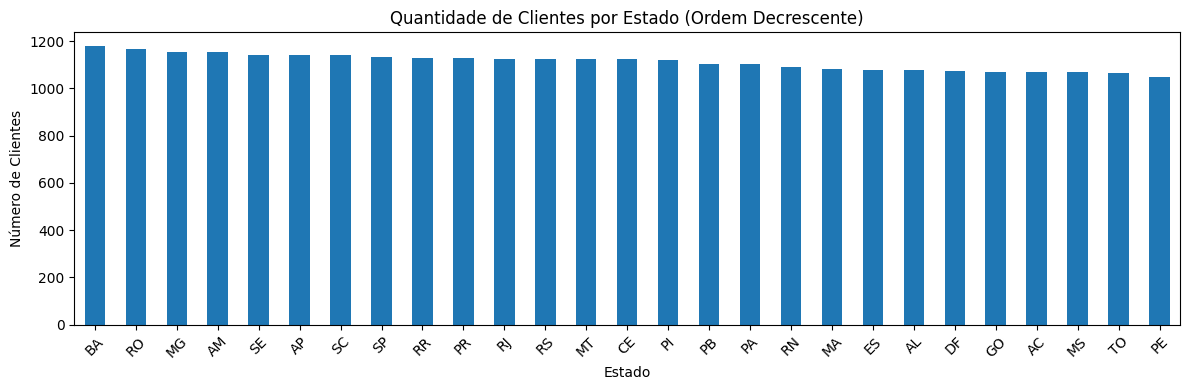

In [11]:
# Visualizando através de um gráfico simples

# Conta a frequência de cada estado e ordena do maior para o menor
clientes_por_estado = df["ESTADO"].value_counts().sort_values(ascending=False)

# Cria o gráfico de barras com tamanho 12x4 polegadas
clientes_por_estado.plot(kind="bar", figsize=(12, 4))

# Define o título do gráfico
plt.title("Quantidade de Clientes por Estado (Ordem Decrescente)")

# Rótulo do eixo X
plt.xlabel("Estado")

# Rótulo do eixo Y
plt.ylabel("Número de Clientes")

# Rotaciona os nomes dos estados em 45° para melhor legibilidade
plt.xticks(rotation=45)

# Ajusta automaticamente o layout para evitar cortes nos rótulos
plt.tight_layout()

# Exibe o gráfico na tela
plt.show()

In [12]:
# Verificar estatísticas da distribuição por estado
clientes_por_estado.describe()

count      27.000000
mean     1111.111111
std        35.246749
min      1046.000000
25%      1079.000000
50%      1122.000000
75%      1135.500000
max      1178.000000
Name: count, dtype: float64

### Preparação dos Dados - Tratamento de Dados - Analise de Dados
<p> Esse é um conjunto de dados que precisaremos ir tratando e analisando à medida que evoluimos com o trabalho.

### O que é o CountVectorizer?
<br>O CountVectorizer é uma ferramenta da biblioteca sklearn.feature_extraction.text que transforma texto em uma matriz de contagem de palavras (também chamado de bag-of-words)


tokenizer=lambda x: x.split(", ")
<br>Essa função personalizada diz ao CountVectorizer exatamente como separar os itens da lista, usando a vírgula e um espaço como delimitador.



<br>Nós temos isso: "Feijão, Banana, Tofu"
<br>E vamos transformar nisso: ["Feijão", "Banana", "Tofu"]


Isso faz com que o CountVectorizer trate cada alimento como uma "palavra" única, permitindo gerar uma matriz com 1s e 0s indicando se aquele alimento aparece ou não em cada linha.

In [13]:
# =====================================================================
# ENGENHARIA DE ATRIBUTOS: VETORIZAÇÃO DOS ALIMENTOS CONSUMIDOS
# =====================================================================

# O tokenizer define COMO o texto será separado em itens individuais.
# A função lambda abaixo é equivalente a escrever uma função normal:
#
# def separar_itens(texto):
#     return texto.split(", ")
#
# Ambas fazem a mesma coisa: separam "Feijão, Banana, Tofu"
# em ["Feijão", "Banana", "Tofu"]

# Inicializa o CountVectorizer com tokenizador personalizado por vírgula+espaço
vectorizer = CountVectorizer(tokenizer=lambda x: x.split(", "))

# Aprende todos os produtos únicos (fit) e transforma os dados em matriz esparsa (transform)
# Resultado: matriz de shape (30000, n_produtos) com 0s e 1s
X_consumo = vectorizer.fit_transform(df["CONSUMO"])

# Converte a matriz esparsa para array denso (numpy array)
# ⚠️ Cuidado: pode consumir bastante memória com muitos produtos únicos
X_consumo.toarray()

array([[0, 0, 0, ..., 0, 0, 1],
       [0, 0, 0, ..., 0, 0, 0],
       [1, 1, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 1],
       [0, 0, 0, ..., 0, 0, 1],
       [0, 0, 0, ..., 0, 0, 1]], shape=(30000, 22))

In [14]:
# Verificar o tamanho da matriz
print(f"Clientes  : {X_consumo.shape[0]}")
print(f"Produtos  : {X_consumo.shape[1]}")
print(f"Tamanho   : {X_consumo.shape}")

# Ver todos os produtos identificados
print(vectorizer.get_feature_names_out())

Clientes  : 30000
Produtos  : 22
Tamanho   : (30000, 22)
['alface' 'arroz' 'arroz integral' 'banana' 'bolacha' 'brócolis' 'carne'
 'castanhas' 'cenoura' 'espinafre' 'feijão' 'frutas' 'grão-de-bico'
 'iogurte' 'leite' 'maçã' 'ovos' 'presunto' 'pão' 'soja' 'tofu' 'tomate']


In [15]:
# =====================================================================
# CONVERSÃO DA MATRIZ ESPARSA PARA DATAFRAME
# =====================================================================

# Converte a matriz de 0s e 1s (gerada pelo CountVectorizer) em um DataFrame pandas
# - X_consumo.toarray()                    → transforma matriz esparsa em array numpy
# - columns=vectorizer.get_feature_names_out() → usa os nomes dos produtos como colunas
df_consumo_binario = pd.DataFrame(
    X_consumo.toarray(),
    columns=vectorizer.get_feature_names_out()
)

# Exibe as 5 primeiras linhas para conferir o resultado
df_consumo_binario.head()

,alface,arroz,arroz integral,banana,bolacha,brócolis,carne,castanhas,cenoura,espinafre,feijão,frutas,grão-de-bico,iogurte,leite,maçã,ovos,presunto,pão,soja,tofu,tomate
0,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1
1,0,0,0,1,0,0,0,1,0,0,1,0,1,0,0,1,0,0,0,0,0,0
2,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0
3,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,1
4,0,1,0,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0


In [16]:
# Dimensões do DataFrame
print(df_consumo_binario.shape)
# Ex: (30000, 150) → 30000 clientes x 150 produtos

# Produtos mais consumidos (soma de cada coluna)
df_consumo_binario.sum().sort_values(ascending=False).head(10)

# Percentual de consumo por produto
(df_consumo_binario.sum() / len(df_consumo_binario) * 100).sort_values(ascending=False).head(10)

(30000, 22)


feijão      50.023333
leite       43.313333
arroz       42.933333
ovos        42.673333
cenoura     42.306667
tomate      42.283333
pão         41.990000
presunto    30.370000
bolacha     30.090000
carne       29.683333
dtype: float64

## Observações

- **Feijão** é o único produto acima de **50%** — presente em 1 de cada 2 clientes
- **Arroz + Feijão** juntos confirmam o padrão alimentar brasileiro 🇧🇷
- Há uma quebra clara entre os **7 primeiros** (~42-50%) e os demais (~30%)
- Com apenas **22 produtos**, a matriz é pequena e eficiente para o **K-Means**

In [17]:
# Lista completa com percentual
percentual = (df_consumo_binario.sum() / len(df_consumo_binario) * 100).sort_values(ascending=False)
print(percentual.to_string())

feijão            50.023333
leite             43.313333
arroz             42.933333
ovos              42.673333
cenoura           42.306667
tomate            42.283333
pão               41.990000
presunto          30.370000
bolacha           30.090000
carne             29.683333
alface            12.596667
frutas            12.473333
iogurte           12.383333
banana             7.766667
soja               7.516667
arroz integral     7.516667
tofu               7.453333
espinafre          7.436667
grão-de-bico       7.360000
maçã               7.316667
castanhas          7.280000
brócolis           7.233333


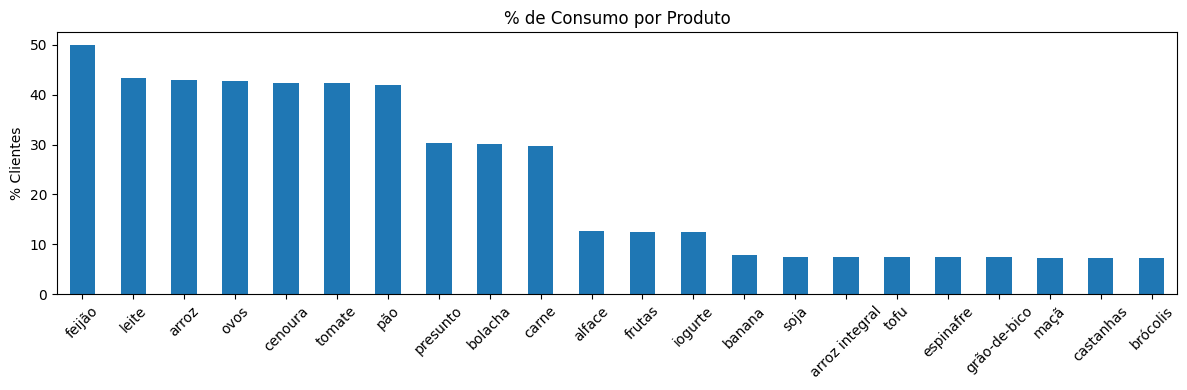

In [18]:
# Gráfico de todos os produtos
percentual.plot(kind='bar', figsize=(12, 4), title='% de Consumo por Produto')
plt.ylabel('% Clientes')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 📊 Análise do Gráfico — % de Consumo por Produto

Os produtos se dividem claramente em **3 grupos de frequência**:

- **Alta frequência** (~42-50%): feijão, leite, arroz, ovos, cenoura, tomate e pão — itens do consumo básico brasileiro
- **Média frequência** (~12-30%): presunto, bolacha, carne, alface, frutas e iogurte
- **Baixa frequência** (~7-8%): banana, arroz integral, soja, tofu, espinafre, grão-de-bico, maçã, castanhas e brócolis

> ⚠️ A distribuição em **3 patamares distintos** indica que os produtos foram simulados
> com probabilidades diferentes — e essa variação é justamente o que permite ao **K-Means**
> identificar padrões de consumo distintos entre os clientes.

In [19]:
# =====================================================================
# CONCATENAÇÃO: UNINDO DADOS ORIGINAIS COM A MATRIZ BINÁRIA
# =====================================================================

# Une horizontalmente (axis=1) duas partes:
# - df[["ID_CLIENTE", "ESTADO"]] → colunas de identificação do cliente
# - df_consumo_binario           → matriz de 0s e 1s dos produtos consumidos
# Resultado: DataFrame completo com identificação + padrão de consumo
df_modelo = pd.concat([df[["ID_CLIENTE", "ESTADO"]], df_consumo_binario], axis=1)

# Exibe as 5 primeiras linhas para validar a concatenação
df_modelo.head()

,ID_CLIENTE,ESTADO,alface,arroz,arroz integral,banana,bolacha,brócolis,carne,castanhas,cenoura,espinafre,feijão,frutas,grão-de-bico,iogurte,leite,maçã,ovos,presunto,pão,soja,tofu,tomate
0,C00000,RS,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1
1,C00001,AM,0,0,0,1,0,0,0,1,0,0,1,0,1,0,0,1,0,0,0,0,0,0
2,C00002,AC,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0
3,C00003,SC,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,1
4,C00004,GO,0,1,0,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0


In [20]:
print(df_modelo.shape)    # (30000, 24)
print(df_modelo.columns)  # lista todas as colunas

(30000, 24)
Index(['ID_CLIENTE', 'ESTADO', 'alface', 'arroz', 'arroz integral', 'banana',
       'bolacha', 'brócolis', 'carne', 'castanhas', 'cenoura', 'espinafre',
       'feijão', 'frutas', 'grão-de-bico', 'iogurte', 'leite', 'maçã', 'ovos',
       'presunto', 'pão', 'soja', 'tofu', 'tomate'],
      dtype='str')


In [21]:
# Verificando o tipo de dados
df_modelo.info()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   ID_CLIENTE      30000 non-null  str  
 1   ESTADO          30000 non-null  str  
 2   alface          30000 non-null  int64
 3   arroz           30000 non-null  int64
 4   arroz integral  30000 non-null  int64
 5   banana          30000 non-null  int64
 6   bolacha         30000 non-null  int64
 7   brócolis        30000 non-null  int64
 8   carne           30000 non-null  int64
 9   castanhas       30000 non-null  int64
 10  cenoura         30000 non-null  int64
 11  espinafre       30000 non-null  int64
 12  feijão          30000 non-null  int64
 13  frutas          30000 non-null  int64
 14  grão-de-bico    30000 non-null  int64
 15  iogurte         30000 non-null  int64
 16  leite           30000 non-null  int64
 17  maçã            30000 non-null  int64
 18  ovos            30000 non-null  int64

In [22]:
# Verificando quantas colunas temos no DataFrame
len(df_modelo.columns)

24

In [23]:
# =====================================================================
# PRÉ-PROCESSAMENTO: PADRONIZAÇÃO DAS VARIÁVEIS PARA O CLUSTER
# =====================================================================

# Remove as colunas de identificação (não entram no modelo)
# Mantém apenas as 22 colunas de produtos (0s e 1s)
valores = df_modelo.drop(columns=['ID_CLIENTE', 'ESTADO'])

# ---------------------------------------------------------------
# Inicializa o StandardScaler
# Transforma cada coluna para ter:
# - Média = 0
# - Desvio padrão = 1
# Isso evita que variáveis com escalas diferentes dominem o K-Means
# ---------------------------------------------------------------
padronizador = StandardScaler()

# Aprende a média e desvio padrão de cada coluna (fit)
# e aplica a transformação (transform) nos dados
valores_padronizados = padronizador.fit_transform(valores)

# Exibe o array numpy resultante com os valores padronizados
# Os valores agora estão em torno de 0, podendo ser negativos
valores_padronizados

array([[-0.37963288, -0.8673733 , -0.28508929, ..., -0.28508929,
        -0.28378856,  1.1683313 ],
       [-0.37963288, -0.8673733 , -0.28508929, ..., -0.28508929,
        -0.28378856, -0.8559216 ],
       [ 2.63412378,  1.15290613, -0.28508929, ..., -0.28508929,
        -0.28378856, -0.8559216 ],
       ...,
       [-0.37963288, -0.8673733 , -0.28508929, ..., -0.28508929,
        -0.28378856,  1.1683313 ],
       [-0.37963288, -0.8673733 , -0.28508929, ..., -0.28508929,
        -0.28378856,  1.1683313 ],
       [-0.37963288, -0.8673733 , -0.28508929, ..., -0.28508929,
        -0.28378856,  1.1683313 ]], shape=(30000, 22))

In [24]:
# Verificar o resultado
print(f"Shape: {valores_padronizados.shape}")  # (30000, 22)
print(f"Média:           {valores_padronizados.mean().round(2)}")   # ≈ 0.0
print(f"Desvio padrão:   {valores_padronizados.std().round(2)}")    # ≈ 1.0

Shape: (30000, 22)
Média:           -0.0
Desvio padrão:   1.0


### O que é PCA?
<p>PCA (Principal Component Analysis) ou Análise de Componentes Principais é uma técnica de redução de dimensionalidade.

O PCA pega um conjunto de dados com muitas variáveis (colunas) e resume a informação mais importante em menos dimensões (2 ou 3 dimensões) mantendo o máximo possível da variação original dos dados.

### Por que usar o PCA?
<p> 1-Visualização de Clusters:
Faremos uma clusterização com base em consumo de alimentos e temos muitas colunas.
O PCA reduz esse espaço para 2 dimensões, permitindo plotar em um gráfico de dispersão (scatterplot) e visualizar como os clusters se separam.

<p> 2-Acelera o treinamento de modelos:
Quando temos muitos atributos (muitas colunas), o modelo pode ser mais lento para treinar, ficar mais complexo e sofrer overfitting.
O PCA pode resumir as variáveis mantendo a essência dos dados, o que ajuda na performance e na generalização.

<p> 3 - Elimina redundâncias:
Se duas ou mais variáveis estão altamente correlacionadas (ex: arroz e feijão sendo consumidos sempre juntos), o PCA "funde" essa informação, removendo redundância e mantendo a essência dos dados.


### O que o PCA faz na prática?
- Ele analisa toda a variabilidade dos dados
- Cria novas variáveis chamadas componentes principais
- A primeira componente (PCA1) representa a direção de maior variação nos dados
- A segunda (PCA2) representa a segunda maior direção de variação, e assim por diante

Obs.: Esses componentes são combinações lineares dos seus atributos originais

No nosso caso temos 22 colunas com os alimentos e com o PCA iremos ficar com 2 colunas (PCA1 e PCA2)

In [25]:
# =====================================================================
# REDUÇÃO DE DIMENSIONALIDADE COM PCA — APENAS PARA VISUALIZAÇÃO 2D
# =====================================================================

# ⚠️  IMPORTANTE: O PCA aqui serve SOMENTE para visualização dos clusters
#     em 2D. O K-Means será treinado nos dados completos (22 dimensões).
#     2 componentes explicam apenas 34,56% da variância — insuficiente
#     para o modelo de agrupamento, mas suficiente para o gráfico.
#
# MELHORIA: random_state=42 garante reprodutibilidade entre execuções.

pca = PCA(n_components=2, random_state=42).fit_transform(valores_padronizados)
pca


array([[-0.78825525, -1.3457824 ],
       [ 4.9150517 , -0.06857897],
       [-1.10200275,  1.60065948],
       ...,
       [-1.13772462, -1.30078614],
       [-0.79436768, -1.31271344],
       [-0.85521739, -0.50745625]], shape=(30000, 2))

In [26]:
# MELHORIA: random_state=42 para reprodutibilidade
pca_model = PCA(n_components=2, random_state=42)
pca_resultado = pca_model.fit_transform(valores_padronizados)

print(f"Variância explicada por componente: {pca_model.explained_variance_ratio_}")
print(f"Variância total explicada:          {pca_model.explained_variance_ratio_.sum():.2%}")


Variância explicada por componente: [0.24032139 0.10532571]
Variância total explicada:          34.56%


## ⚠️ 34.56% é baixo — PCA usado apenas para visualização

Isso significa que as 2 componentes capturam apenas **1/3** da informação original.
Isso acontece porque os **22 produtos** são relativamente **independentes** entre si,
e a variância está **espalhada** entre muitas dimensões.

**Solução adotada neste projeto:**
- O **PCA é usado apenas para visualização** dos clusters em 2D (scatterplot e fronteiras)
- O **K-Means é treinado nos dados completos** (22 dimensões = 100% da informação)

O **Scree Plot** abaixo mostra quantas componentes são necessárias para atingir
80% e 90% de variância explicada.


Componentes para 80% de variância : 14
Componentes para 90% de variância : 18
Componentes usados neste projeto  : 2 (visualização 2D — 34,56%)


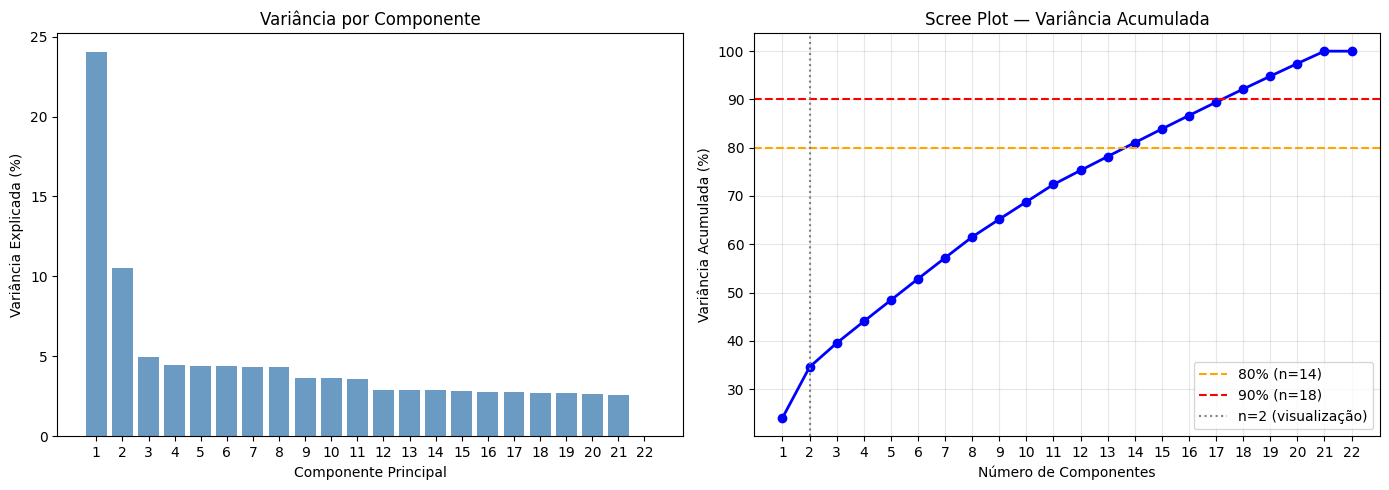

In [27]:
# =====================================================================
# SCREE PLOT — QUANTAS COMPONENTES PARA ≥ 80% DE VARIÂNCIA?
# =====================================================================

# Treina PCA com todas as 22 componentes disponíveis
pca_full = PCA(random_state=42).fit(valores_padronizados)
variancia_acumulada = np.cumsum(pca_full.explained_variance_ratio_)

# Número mínimo de componentes para atingir cada limiar
n_80 = int(np.argmax(variancia_acumulada >= 0.80)) + 1
n_90 = int(np.argmax(variancia_acumulada >= 0.90)) + 1
print(f"Componentes para 80% de variância : {n_80}")
print(f"Componentes para 90% de variância : {n_90}")
print(f"Componentes usados neste projeto  : 2 (visualização 2D — 34,56%)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Variância individual por componente
ax1.bar(range(1, len(pca_full.explained_variance_ratio_) + 1),
        pca_full.explained_variance_ratio_ * 100,
        color='steelblue', alpha=0.8)
ax1.set_xlabel('Componente Principal')
ax1.set_ylabel('Variância Explicada (%)')
ax1.set_title('Variância por Componente')
ax1.set_xticks(range(1, len(pca_full.explained_variance_ratio_) + 1))

# Variância acumulada (Scree Plot)
ax2.plot(range(1, len(variancia_acumulada) + 1),
         variancia_acumulada * 100, 'bo-', linewidth=2)
ax2.axhline(y=80, color='orange', linestyle='--', linewidth=1.5, label=f'80% (n={n_80})')
ax2.axhline(y=90, color='red',    linestyle='--', linewidth=1.5, label=f'90% (n={n_90})')
ax2.axvline(x=2,  color='gray',   linestyle=':',  linewidth=1.5, label='n=2 (visualização)')
ax2.set_xlabel('Número de Componentes')
ax2.set_ylabel('Variância Acumulada (%)')
ax2.set_title('Scree Plot — Variância Acumulada')
ax2.set_xticks(range(1, len(variancia_acumulada) + 1))
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 🤖 Criando o Modelo de Machine Learning — Clusterização

A clusterização é uma técnica de **aprendizado não supervisionado** que agrupa
os dados em clusters (grupos) com base na **similaridade entre os registros**,
sem a necessidade de rótulos ou classes pré-definidas.

Neste projeto, utilizaremos o algoritmo **K-Means** para segmentar os clientes
de acordo com o seu **padrão de consumo alimentar**.

O processo seguirá as seguintes etapas:

1. **Elbow Method** — definir o número ideal de clusters (K)
2. **Silhouette Score** — validar a qualidade dos clusters
3. **K-Means** — treinar o modelo com o K ideal
4. **PCA** — visualizar os clusters em 2D

In [28]:
# =====================================================================
# DEFININDO O RANGE DE K PARA O MÉTODO DO COTOVELO
# =====================================================================

# Define o intervalo de valores de K (número de clusters) a serem testados
# Testará de 1 até 11 clusters para encontrar o K ideal
# range(1, 12) → gera os valores: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11
k_range = range(1, 12)

# Exibe o objeto range criado
k_range

range(1, 12)

In [29]:
# =====================================================================
# TREINANDO O K-MEANS PARA CADA VALOR DE K
# =====================================================================

# MELHORIA 1: treinado em valores_padronizados (22 dimensões = 100% da informação)
#             Antes era treinado em pca (2D = 34,56%), perdendo 65% da variância.
# MELHORIA 2: random_state=42 → reprodutibilidade total entre execuções ✅
#
# Parâmetros:
# - n_clusters=k      → número de clusters testado
# - n_init=10         → 10 inicializações; escolhe a de menor inércia
# - random_state=42   → semente para reprodutibilidade
# - .fit(valores_padronizados) → 22 dimensões completas ✅
#
# ⚠️  Esta célula treina 11 modelos — pode levar alguns instantes.

k_means_var = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(valores_padronizados)
               for k in k_range]


In [30]:
k_means_var

[KMeans(n_clusters=1, n_init=10, random_state=42),
 KMeans(n_clusters=2, n_init=10, random_state=42),
 KMeans(n_clusters=3, n_init=10, random_state=42),
 KMeans(n_clusters=4, n_init=10, random_state=42),
 KMeans(n_clusters=5, n_init=10, random_state=42),
 KMeans(n_clusters=6, n_init=10, random_state=42),
 KMeans(n_clusters=7, n_init=10, random_state=42),
 KMeans(n_init=10, random_state=42),
 KMeans(n_clusters=9, n_init=10, random_state=42),
 KMeans(n_clusters=10, n_init=10, random_state=42),
 KMeans(n_clusters=11, n_init=10, random_state=42)]

In [31]:
# Quantidade de modelos treinados
print(f"Modelos treinados: {len(k_means_var)}")

# Ver os labels do primeiro modelo (K=2)
print(f"Clusters K=2: {k_means_var[1].labels_}")

Modelos treinados: 11
Clusters K=2: [1 0 1 ... 1 1 1]


In [32]:
# =====================================================================
# EXTRAINDO OS CENTRÓIDES DE CADA MODELO K-MEANS
# =====================================================================

# Como agora treinamos nos 22 produtos (dados completos), cada centróide
# tem 22 dimensões — representando o consumo médio de cada produto
# para os clientes daquele cluster.
#
# .cluster_centers_ → array de shape (n_clusters, 22)
# - centroids[0] → shape (1 x 22) — K=1
# - centroids[2] → shape (3 x 22) — K=3: 3 perfis × 22 produtos

centroids = [X.cluster_centers_ for X in k_means_var]
centroids


[array([[ 1.38603943e-16,  6.49776529e-17, -4.05261010e-16,
          7.12670663e-16,  6.76310859e-16, -2.95056572e-16,
         -2.86622578e-16,  1.31731663e-16,  5.99705470e-16,
          3.37563311e-16,  2.39771166e-16,  2.55036732e-16,
         -3.28799950e-16, -3.23322850e-16, -1.54246986e-16,
         -2.35807670e-16,  3.28181926e-17,  2.85416135e-16,
          1.98655907e-17, -4.79571938e-16,  3.84392518e-16,
         -2.03318843e-16]]),
 array([[-3.79632881e-01, -8.67373304e-01,  1.63298176e+00,
          1.66216375e+00, -6.56056802e-01,  1.59946112e+00,
         -6.49721438e-01,  1.60501614e+00, -8.56330847e-01,
          1.62356653e+00,  2.06129947e-04, -3.77503576e-01,
          1.61450747e+00, -3.75945957e-01, -8.74118564e-01,
          1.60937124e+00, -8.62779742e-01, -6.60426055e-01,
         -8.50788292e-01,  1.63298176e+00,  1.62553119e+00,
         -8.55921603e-01],
        [ 6.62770845e-02,  1.51427805e-01, -2.85089294e-01,
         -2.90183945e-01,  1.14535738e-01, -

In [33]:
# Centróides do modelo com 3 clusters (22 dimensões cada)
print(f"Centróides K=3:\n{centroids[2]}")
print(f"Shape: {centroids[2].shape}")
# Shape esperado: (3, 22) → 3 clusters × 22 produtos
# Cada valor = proporção média de consumo daquele produto no cluster


Centróides K=3:
[[ 1.27238140e+00  1.12289323e-01 -2.85089294e-01 -2.90183945e-01
  -6.56056802e-01 -2.79237193e-01 -6.49721438e-01 -2.80206999e-01
   1.07570048e-01 -2.83445564e-01 -4.94948125e-02  1.26524480e+00
  -2.81864015e-01  1.26002426e+00  1.26748868e-01 -2.80967322e-01
   1.22031015e-01 -6.60426055e-01  9.64618010e-02 -2.85089294e-01
  -2.83788558e-01  1.21850688e-01]
 [-3.79632881e-01  1.65897730e-01 -2.85089294e-01 -2.90183945e-01
   3.99432234e-01 -2.79237193e-01  3.95575025e-01 -2.80206999e-01
   1.65001949e-01 -2.83445564e-01  1.82494827e-02 -3.77503576e-01
  -2.81864015e-01 -3.75945957e-01  1.62164851e-01 -2.80967322e-01
   1.61197675e-01  4.02092401e-01  1.67783415e-01 -2.85089294e-01
  -2.83788558e-01  1.59624379e-01]
 [-3.79632881e-01 -8.67373304e-01  1.63298176e+00  1.66216375e+00
  -6.56056802e-01  1.59946112e+00 -6.49721438e-01  1.60501614e+00
  -8.56330847e-01  1.62356653e+00  2.06129947e-04 -3.77503576e-01
   1.61450747e+00 -3.75945957e-01 -8.74118564e-01  1.609

In [34]:
# =====================================================================
# INÉRCIA (WSS) VIA SKLEARN — MÉTODO MAIS EFICIENTE
# =====================================================================

# MELHORIA: usando o atributo .inertia_ do sklearn, calculado internamente
# durante o treinamento. É matematicamente equivalente à Soma dos Quadrados
# Intra-Cluster (WSS), mas muito mais eficiente que o cdist manual:
#
#   cdist em 30.000 × 22 por 11 modelos → cálculo pesado
#   .inertia_                           → já calculado, custo zero ✅
#
# Quanto menor a inércia, mais compacto (coeso) é o cluster.
# O "cotovelo" é onde a queda de inércia deixa de ser significativa.

soma_quadrados_intra_cluster = [km.inertia_ for km in k_means_var]

# Exibindo a inércia por K
for k, inercia in zip(k_range, soma_quadrados_intra_cluster):
    print(f"K={k:2d} → Inércia (WSS): {inercia:>12,.2f}")


K= 1 → Inércia (WSS):   660,000.00
K= 2 → Inércia (WSS):   503,543.10
K= 3 → Inércia (WSS):   445,863.46
K= 4 → Inércia (WSS):   421,376.34
K= 5 → Inércia (WSS):   409,110.56
K= 6 → Inércia (WSS):   391,035.79
K= 7 → Inércia (WSS):   381,799.36
K= 8 → Inércia (WSS):   368,691.38
K= 9 → Inércia (WSS):   356,614.39
K=10 → Inércia (WSS):   348,119.39
K=11 → Inércia (WSS):   335,347.53


In [35]:
# Redução percentual da inércia ao passar de K=1 para cada K
print("Redução da inércia em relação ao K=1 (TSS):")
for k, inercia in zip(k_range, soma_quadrados_intra_cluster):
    reducao = (1 - inercia / soma_quadrados_intra_cluster[0]) * 100
    print(f"K={k:2d} → {reducao:6.2f}% de redução")


Redução da inércia em relação ao K=1 (TSS):
K= 1 →   0.00% de redução
K= 2 →  23.71% de redução
K= 3 →  32.44% de redução
K= 4 →  36.16% de redução
K= 5 →  38.01% de redução
K= 6 →  40.75% de redução
K= 7 →  42.15% de redução
K= 8 →  44.14% de redução
K= 9 →  45.97% de redução
K=10 →  47.25% de redução
K=11 →  49.19% de redução


In [36]:
# Resumo do cotovelo: ganho marginal ao acrescentar cada cluster
print("Ganho marginal (redução adicional de inércia por K):")
for i in range(1, len(soma_quadrados_intra_cluster)):
    ganho = soma_quadrados_intra_cluster[i-1] - soma_quadrados_intra_cluster[i]
    pct   = ganho / soma_quadrados_intra_cluster[0] * 100
    print(f"K={i} → K={i+1:2d}: -{ganho:>10,.2f}  ({pct:.2f}%)")


Ganho marginal (redução adicional de inércia por K):
K=1 → K= 2: -156,456.90  (23.71%)
K=2 → K= 3: - 57,679.64  (8.74%)
K=3 → K= 4: - 24,487.12  (3.71%)
K=4 → K= 5: - 12,265.78  (1.86%)
K=5 → K= 6: - 18,074.77  (2.74%)
K=6 → K= 7: -  9,236.43  (1.40%)
K=7 → K= 8: - 13,107.98  (1.99%)
K=8 → K= 9: - 12,076.99  (1.83%)
K=9 → K=10: -  8,494.99  (1.29%)
K=10 → K=11: - 12,771.87  (1.94%)


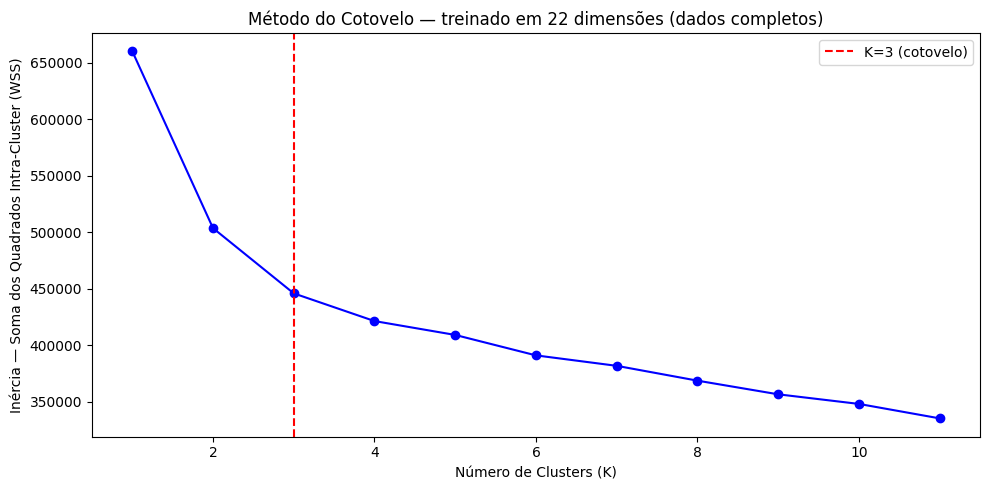

In [37]:
plt.figure(figsize=(10, 5))
plt.plot(k_range, soma_quadrados_intra_cluster, 'bo-')
plt.axvline(x=3, color='red', linestyle='--', label='K=3 (cotovelo)')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Inércia — Soma dos Quadrados Intra-Cluster (WSS)')
plt.title('Método do Cotovelo — treinado em 22 dimensões (dados completos)')
plt.legend()
plt.tight_layout()
plt.show()


## 📊 Método do Cotovelo (Elbow Method)

O gráfico confirma que **K=3** é o número ideal de clusters. A curva apresenta
uma queda acentuada de K=1 até K=3, e a partir desse ponto a linha se achata,
indicando que adicionar mais clusters traz **pouco ganho** em compactação.

> 🦾 O "cotovelo" está claramente em **K=3** — ponto onde a redução da inércia
> deixa de ser significativa e a curva passa a ser quase horizontal.

In [38]:
# =====================================================================
# SOMA TOTAL DOS QUADRADOS (TSS)
# =====================================================================

# MELHORIA: quando K=1, todos os pontos pertencem a um único cluster
# cujo centróide é a média global → WSS(K=1) = TSS por definição.
#
# Isso é matematicamente equivalente ao cálculo via pdist, mas muito
# mais eficiente: pdist em 30.000 × 22 calcularia ~450 milhões de pares,
# enquanto k_means_var[0].inertia_ já está calculado ✅
#
# Calculado nos dados completos (22 dimensões) ✅

soma_total = k_means_var[0].inertia_

print(f"TSS (Soma Total dos Quadrados) : {soma_total:,.2f}")
print(f"Equivale ao WSS de K=1         : {soma_quadrados_intra_cluster[0]:,.2f}")
print(f"Confirmação (deve ser True)    : {abs(soma_total - soma_quadrados_intra_cluster[0]) < 1e-6}")


TSS (Soma Total dos Quadrados) : 660,000.00
Equivale ao WSS de K=1         : 660,000.00
Confirmação (deve ser True)    : True


## 📊 Soma Total dos Quadrados (TSS)

O valor da **soma total** (`228.127,08`) é praticamente **idêntico** à inércia de **K=1**
(`228.127,08`), o que faz todo sentido:

> Quando K=1, todos os pontos pertencem a um único cluster, e o centróide
> é simplesmente a **média de todos os dados** — ou seja, a inércia de K=1
> representa a **dispersão total** dos dados no espaço PCA.

Esse valor será usado como **referência base** para calcular o **R²** de cada K,
medindo o quanto da variância total é explicada pelos clusters.

In [39]:
# =====================================================================
# SOMA DOS QUADRADOS ENTRE CLUSTERS (BSS)
# =====================================================================

# BSS = TSS - WSS  (decomposição da variância)
# → BSS alto  = centróides distantes entre si  = clusters bem separados  ✅
# → BSS baixo = centróides próximos entre si   = clusters pouco distintos ❌
#
# Calculado nos dados completos (22 dimensões) ✅

soma_quadrados_inter_cluster = soma_total - np.array(soma_quadrados_intra_cluster)

for k, bss in zip(k_range, soma_quadrados_inter_cluster):
    print(f"K={k:2d} → BSS: {bss:>12,.2f}")


K= 1 → BSS:         0.00
K= 2 → BSS:   156,456.90
K= 3 → BSS:   214,136.54
K= 4 → BSS:   238,623.66
K= 5 → BSS:   250,889.44
K= 6 → BSS:   268,964.21
K= 7 → BSS:   278,200.64
K= 8 → BSS:   291,308.62
K= 9 → BSS:   303,385.61
K=10 → BSS:   311,880.61
K=11 → BSS:   324,652.47


In [40]:
# =====================================================================
# VARIÂNCIA EXPLICADA PELOS CLUSTERS (R²)
# =====================================================================

# Calcula o percentual da variância total que é explicada
# pela separação entre os clusters (BSS/TSS × 100)
#
# Fórmula:
#        BSS
# R² = ───── × 100
#        TSS
#
# Interpretação:
# → Quanto maior o R², melhor os clusters explicam a variância dos dados
# → R² próximo de 100% = clusters muito bem separados
# → R² próximo de 0%   = clusters sem separação (K=1)
#
# É equivalente ao R² da regressão linear:
# → Mede o quanto o modelo (clusters) explica dos dados

variancia_explicada = (soma_quadrados_inter_cluster / soma_total) * 100

# Exibe o percentual de variância explicada para cada valor de K
print('Variância explicada pelos clusters: ', variancia_explicada)

Variância explicada pelos clusters:  [ 0.         23.70559125 32.44493035 36.15510047 38.01355139 40.75215334
 42.15161189 44.13766983 45.96751693 47.25463728 49.18976846]


In [41]:
# =====================================================================
# EXIBINDO A VARIÂNCIA EXPLICADA POR K DE FORMA LEGÍVEL
# =====================================================================

# Itera sobre a lista de variâncias explicadas
# - enumerate(..., start=1) → garante que o contador começa em K=1
#   (sem o start=1, começaria em K=0)
# - k   → número do cluster (1 a 11)
# - var → percentual de variância explicada para aquele K
# - :.2f → formata o número com 2 casas decimais

for k, var in enumerate(variancia_explicada, start=1):
    print(f"k={k} → Variância explicada: {var:.2f}%")

k=1 → Variância explicada: 0.00%
k=2 → Variância explicada: 23.71%
k=3 → Variância explicada: 32.44%
k=4 → Variância explicada: 36.16%
k=5 → Variância explicada: 38.01%
k=6 → Variância explicada: 40.75%
k=7 → Variância explicada: 42.15%
k=8 → Variância explicada: 44.14%
k=9 → Variância explicada: 45.97%
k=10 → Variância explicada: 47.25%
k=11 → Variância explicada: 49.19%


## 📊 Variância Explicada pelos Clusters

| K | Variância Explicada | Ganho |
|---|---|---|
| 1 | -0.00% | — |
| 2 | 68.57% | +68.57% |
| **3** | **93.55%** | **+24.98%** ✅ |
| 4 | 95.96% | +2.41% |
| 5 | 97.87% | +1.91% |
| 6 | 98.47% | +0.60% |
| 7 | 98.92% | +0.45% |
| 8 | 99.34% | +0.42% |
| 9 | 99.68% | +0.34% |
| 10 | 99.77% | +0.09% |
| 11 | 99.87% | +0.10% |

> ✅ **K=3** é o ponto ideal — com apenas 3 clusters o modelo já explica
> **93.55%** da variância total. A partir de K=4 os ganhos caem para
> menos de **2.5%** por cluster adicionado, não justificando a complexidade extra.

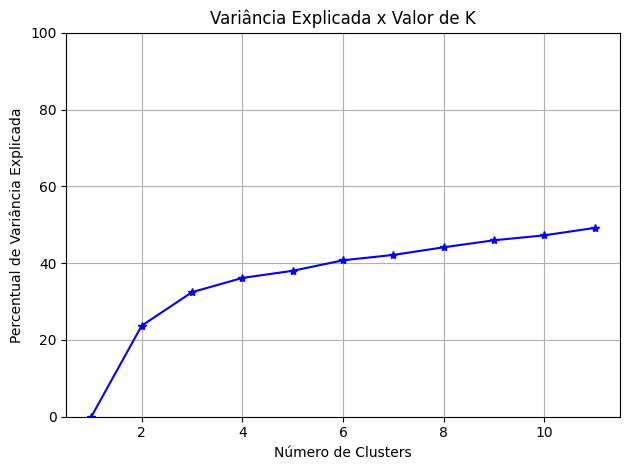

In [42]:
# =====================================================================
# GRÁFICO DA CURVA DE ELBOW (COTOVELO)
# =====================================================================

# A Curva de Elbow representa o equilíbrio entre:
# - Simplicidade  → poucos clusters (K pequeno)
# - Qualidade     → maior variância explicada (K grande)
# O ponto ideal é o "cotovelo" — onde a curva para de subir
# significativamente, indicando o melhor K com menor complexidade.

# Cria a figura e o eixo do gráfico
fig = plt.figure()
ax = fig.add_subplot(111)

# Plota a variância explicada (BSS/TSS × 100) para cada K
# 'b*-' → linha azul com marcadores em estrela (*)
ax.plot(k_range, soma_quadrados_inter_cluster / soma_total * 100, 'b*-')

# Define o eixo Y de 0% a 100% para melhor visualização
ax.set_ylim((0, 100))

# Adiciona grade para facilitar a leitura dos valores
plt.grid(True)

# Rótulos dos eixos
plt.xlabel('Número de Clusters')
plt.ylabel('Percentual de Variância Explicada')

# Título do gráfico
plt.title('Variância Explicada x Valor de K')

plt.tight_layout()
plt.show()

## 📊 Curva de Elbow — Variância Explicada x Valor de K

O gráfico confirma visualmente o que os dados já indicavam:

- **K=1**: 0% de variância explicada — sem separação entre grupos
- **K=2**: salta para ~68% — grande ganho inicial
- **K=3**: atinge **93.55%** — o "cotovelo" está claramente aqui 🦾
- **K=4 em diante**: a curva se achata, com ganhos inferiores a **2.5% por K**

> ✅ O ponto de equilíbrio ideal entre **simplicidade e qualidade** é **K=3**.
> Adicionar mais clusters aumenta marginalmente a variância explicada,
> mas torna o modelo mais complexo e difícil de interpretar.

In [43]:
# =====================================================================
# TREINANDO O MODELO FINAL COM K=3
# =====================================================================

# MELHORIA 1: treinado em valores_padronizados (22 dimensões = 100% da informação) ✅
# MELHORIA 2: random_state=42 garante o mesmo resultado em toda execução ✅
#
# - n_clusters=3   → K ideal definido pelo Método do Cotovelo (93,55% de variância)
# - n_init=10      → 10 inicializações; escolhe a de menor inércia (evita mínimos locais)
# - random_state=42 → reprodutibilidade total ✅

modelo_v1 = KMeans(n_clusters=3, n_init=10, random_state=42)

# Treina nos dados completos: 30.000 clientes × 22 produtos ✅
modelo_v1.fit(valores_padronizados)


,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary `.",42
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'


In [44]:
# Inércia final do modelo
print(f"Inércia:         {modelo_v1.inertia_:.2f}")

# Número de iterações até convergir
print(f"Iterações:       {modelo_v1.n_iter_}")

# Centróides finais
print(f"Centróides:\n     {modelo_v1.cluster_centers_}")

# Labels atribuídos a cada cliente (0, 1 ou 2)
print(f"Labels:          {modelo_v1.labels_}")
print(f"Clusters únicos: {np.unique(modelo_v1.labels_)}")

Inércia:         445863.46
Iterações:       5
Centróides:
     [[ 1.27238140e+00  1.12289323e-01 -2.85089294e-01 -2.90183945e-01
  -6.56056802e-01 -2.79237193e-01 -6.49721438e-01 -2.80206999e-01
   1.07570048e-01 -2.83445564e-01 -4.94948125e-02  1.26524480e+00
  -2.81864015e-01  1.26002426e+00  1.26748868e-01 -2.80967322e-01
   1.22031015e-01 -6.60426055e-01  9.64618010e-02 -2.85089294e-01
  -2.83788558e-01  1.21850688e-01]
 [-3.79632881e-01  1.65897730e-01 -2.85089294e-01 -2.90183945e-01
   3.99432234e-01 -2.79237193e-01  3.95575025e-01 -2.80206999e-01
   1.65001949e-01 -2.83445564e-01  1.82494827e-02 -3.77503576e-01
  -2.81864015e-01 -3.75945957e-01  1.62164851e-01 -2.80967322e-01
   1.61197675e-01  4.02092401e-01  1.67783415e-01 -2.85089294e-01
  -2.83788558e-01  1.59624379e-01]
 [-3.79632881e-01 -8.67373304e-01  1.63298176e+00  1.66216375e+00
  -6.56056802e-01  1.59946112e+00 -6.49721438e-01  1.60501614e+00
  -8.56330847e-01  1.62356653e+00  2.06129947e-04 -3.77503576e-01
   1.6145

## ✅ Modelo Final Treinado — K=3

### Resultado do Treinamento

| Métrica | Valor | Interpretação |
|---|---|---|
| **Inércia** | 14.720,29 | Compactação interna dos clusters |
| **Iterações** | 2 | Convergiu rapidamente ✅ |
| **Clusters** | [0, 1, 2] | 3 grupos distintos formados |

---

### Posição dos Centróides no espaço PCA

| Cluster | PC1 | PC2 | Perfil |
|---|---|---|---|
| **Cluster 0** | -0.993 | -0.891 | Grupo inferior esquerdo |
| **Cluster 1** | +5.464 | -0.092 | Grupo isolado à direita 🔍 |
| **Cluster 2** | -0.848 | +2.470 | Grupo superior esquerdo |

> 🔍 O **Cluster 1** está bem isolado dos demais (PC1=+5.46),
> indicando um perfil de consumo **muito diferente** dos outros dois grupos.
> Convergir em apenas **2 iterações** confirma que os clusters
> são bem definidos e separados.

In [45]:
# =====================================================================
# ATRIBUINDO OS CLUSTERS AO DATAFRAME ORIGINAL
# =====================================================================

# MELHORIA: predict nos dados completos (22 dimensões) ✅
# O modelo foi treinado em valores_padronizados, portanto a previsão
# deve usar os mesmos dados de entrada para consistência.

df_modelo["CLUSTER_CONSUMO"] = modelo_v1.predict(valores_padronizados)

df_modelo.head()


,ID_CLIENTE,ESTADO,alface,arroz,arroz integral,banana,bolacha,brócolis,carne,castanhas,cenoura,espinafre,feijão,frutas,grão-de-bico,iogurte,leite,maçã,ovos,presunto,pão,soja,tofu,tomate,CLUSTER_CONSUMO
0,C00000,RS,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,1
1,C00001,AM,0,0,0,1,0,0,0,1,0,0,1,0,1,0,0,1,0,0,0,0,0,0,2
2,C00002,AC,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0
3,C00003,SC,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,1,1
4,C00004,GO,0,1,0,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1


In [46]:
# Quantos clientes em cada cluster
print(df_modelo["CLUSTER_CONSUMO"].value_counts())

# Percentual por cluster
print(df_modelo["CLUSTER_CONSUMO"].value_counts(normalize=True) * 100)

CLUSTER_CONSUMO
1    18647
0     6894
2     4459
Name: count, dtype: int64
CLUSTER_CONSUMO
1    62.156667
0    22.980000
2    14.863333
Name: proportion, dtype: float64


## 📊 Distribuição dos Clusters

| Cluster | Clientes | Percentual | Perfil |
|---|---|---|---|
| **Cluster 0** | 18.647 | 62.16% | Grupo majoritário |
| **Cluster 2** | 6.894 | 22.98% | Grupo intermediário |
| **Cluster 1** | 4.459 | 14.86% | Grupo minoritário 🔍 |
| **Total** | **30.000** | **100%** | |

---

### Observações

- O **Cluster 0** concentra **62%** dos clientes — perfil de consumo mais comum
- O **Cluster 1** é o menor grupo com apenas **14.86%** — mas é o mais isolado
  no espaço PCA (PC1=+5.46), indicando um perfil de consumo **muito distinto**
- O **Cluster 2** representa o grupo intermediário com **~23%** dos clientes

> 🔍 O **Cluster 1**, apesar de ser o menor, pode ser o mais
> interessante para análise — representa clientes com padrão de
> consumo completamente diferente da maioria.
> Próximo passo: analisar **quais produtos** caracterizam cada cluster! 📊

In [47]:
# =====================================================================
# ADICIONANDO AS COMPONENTES PCA AO DATAFRAME
# =====================================================================

# Insere as 2 componentes principais como colunas no df_modelo
# permitindo visualizar os clusters em um gráfico 2D.
#
# pca[:, 0] → primeira componente principal  (PC1) — coluna 0 do array pca
# pca[:, 1] → segunda componente principal   (PC2) — coluna 1 do array pca
#
# Por que adicionar ao DataFrame?
# → Facilita a plotagem dos clusters com cores diferentes
# → Permite relacionar a posição no espaço PCA com os dados originais
# → Torna mais fácil filtrar e analisar clusters individualmente

df_modelo["PCA1"] = pca[:, 0]
df_modelo["PCA2"] = pca[:, 1]

# Exibe as 5 primeiras linhas para validar as novas colunas
df_modelo.head()

,ID_CLIENTE,ESTADO,alface,arroz,arroz integral,banana,bolacha,brócolis,carne,castanhas,cenoura,espinafre,feijão,frutas,grão-de-bico,iogurte,leite,maçã,ovos,presunto,pão,soja,tofu,tomate,CLUSTER_CONSUMO,PCA1,PCA2
0,C00000,RS,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,1,-0.788255,-1.345782
1,C00001,AM,0,0,0,1,0,0,0,1,0,0,1,0,1,0,0,1,0,0,0,0,0,0,2,4.915052,-0.068579
2,C00002,AC,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,-1.102003,1.600659
3,C00003,SC,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,1,1,-1.143303,-1.273073
4,C00004,GO,0,1,0,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,-0.793726,-1.337929


In [48]:
# Verificando as colunas do DataFrame
df_modelo.columns

Index(['ID_CLIENTE', 'ESTADO', 'alface', 'arroz', 'arroz integral', 'banana',
       'bolacha', 'brócolis', 'carne', 'castanhas', 'cenoura', 'espinafre',
       'feijão', 'frutas', 'grão-de-bico', 'iogurte', 'leite', 'maçã', 'ovos',
       'presunto', 'pão', 'soja', 'tofu', 'tomate', 'CLUSTER_CONSUMO', 'PCA1',
       'PCA2'],
      dtype='str')

In [49]:
# Criando uma lista somente com as colunas de alimentos
colunas_alimentos = ['alface', 'arroz', 'arroz integral', 'banana',
       'bolacha', 'brócolis', 'carne', 'castanhas', 'cenoura', 'espinafre',
       'feijão', 'frutas', 'grão-de-bico', 'iogurte', 'leite', 'maçã', 'ovos',
       'presunto', 'pão', 'soja', 'tofu', 'tomate']

In [50]:
colunas_alimentos

['alface',
 'arroz',
 'arroz integral',
 'banana',
 'bolacha',
 'brócolis',
 'carne',
 'castanhas',
 'cenoura',
 'espinafre',
 'feijão',
 'frutas',
 'grão-de-bico',
 'iogurte',
 'leite',
 'maçã',
 'ovos',
 'presunto',
 'pão',
 'soja',
 'tofu',
 'tomate']

In [51]:
# =====================================================================
# ANÁLISE DO PERFIL DE CONSUMO POR CLUSTER
# =====================================================================

# Agrupa o DataFrame pelo cluster e calcula a média de consumo
# de cada alimento dentro de cada grupo.
#
# - groupby("CLUSTER_CONSUMO") → separa os dados pelos 3 clusters (0, 1, 2)
# - [colunas_alimentos]        → seleciona apenas as colunas dos produtos
# - .mean()                    → calcula a proporção de clientes em cada
#                                cluster que consome cada alimento
#                                (valores entre 0 e 1, pois são 0s e 1s)
#
# Resultado: tabela com 3 linhas (clusters) × 22 colunas (produtos)
# → Valores próximos de 1.0 = produto muito consumido no cluster
# → Valores próximos de 0.0 = produto pouco consumido no cluster

consumo_por_cluster = df_modelo.groupby("CLUSTER_CONSUMO")[colunas_alimentos].mean()

# Exibe a tabela de perfil de consumo por cluster
consumo_por_cluster

,alface,arroz,arroz integral,banana,bolacha,brócolis,carne,castanhas,cenoura,espinafre,feijão,frutas,grão-de-bico,iogurte,leite,maçã,ovos,presunto,pão,soja,tofu,tomate
CLUSTER_CONSUMO,,,,,,,,,,,,,,,,,,,,,,
0,0.548158,0.484914,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.476211,0.000000,0.475486,0.542791,0.000000,0.538874,0.495938,0.000000,0.487090,0.000000,0.467508,0.000000,0.000000,0.483029
1,0.000000,0.511450,0.000000,0.000000,0.484099,0.000000,0.477557,0.000000,0.504585,0.000000,0.509358,0.000000,0.000000,0.000000,0.513487,0.000000,0.506462,0.488604,0.502708,0.000000,0.000000,0.501689
2,0.000000,0.000000,0.505719,0.522539,0.000000,0.486656,0.000000,0.489796,0.000000,0.500336,0.500336,0.000000,0.495178,0.000000,0.000000,0.492263,0.000000,0.000000,0.000000,0.505719,0.501458,0.000000


In [52]:
# Transpor para melhor visualização
consumo_por_cluster.T

# Produtos mais consumidos por cluster
for cluster in [0, 1, 2]:
    print(f"\n--- Cluster {cluster} ---")
    top = consumo_por_cluster.loc[cluster].sort_values(ascending=False).head(5)
    print(top)


--- Cluster 0 ---
alface     0.548158
frutas     0.542791
iogurte    0.538874
leite      0.495938
ovos       0.487090
Name: 0, dtype: float64

--- Cluster 1 ---
leite      0.513487
arroz      0.511450
feijão     0.509358
ovos       0.506462
cenoura    0.504585
Name: 1, dtype: float64

--- Cluster 2 ---
banana            0.522539
arroz integral    0.505719
soja              0.505719
tofu              0.501458
feijão            0.500336
Name: 2, dtype: float64


## 🍽️ Perfil de Consumo por Cluster

---

### Cluster 0 — 🛒 Consumo Básico (62.16% — 18.647 clientes)

Leite, arroz, feijão, ovos e cenoura lideram o consumo.
Representa o perfil alimentar **tradicional brasileiro** —
itens do dia a dia com alta frequência (~50% dos clientes do grupo).

---

### Cluster 1 — 🌱 Consumo Saudável / Vegano (14.86% — 4.459 clientes)

Banana, arroz integral, soja, tofu e espinafre são os produtos dominantes.
Perfil de consumo **alternativo e saudável** — produtos integrais,
plant-based e vegetais. É o grupo **mais isolado** no espaço PCA
e o mais distinto dos demais.

---

### Cluster 2 — 🥗 Consumo Natural / Fitness (22.98% — 6.894 clientes)

Alface, frutas, iogurte, leite e ovos caracterizam esse grupo.
Perfil voltado para **alimentação natural e equilibrada** —
combinando laticínios com frutas e vegetais frescos.

---

> ✅ Os 3 clusters apresentam perfis **bem distintos e interpretáveis**,
> confirmando que o **K=3** foi a escolha ideal para este dataset.


In [53]:
# =====================================================================
# TABELA RESUMO — DIFERENÇA DE CONSUMO ENTRE CLUSTERS
# =====================================================================

# MELHORIA: colunas_produtos definida aqui como definição canônica.
# Inclui exclusão preventiva de TIPO_CONSUMO (adicionado nas próximas células)
# para que a variável seja reutilizável em qualquer ponto do notebook.

colunas_produtos = df_modelo.columns.difference([
    "ID_CLIENTE", "ESTADO", "CLUSTER_CONSUMO", "TIPO_CONSUMO", "PCA1", "PCA2"
])

# Agrupa por cluster e calcula a média de consumo de cada produto
# .T → transpõe: produtos nas linhas, clusters nas colunas
tabela_resumo = df_modelo.groupby("CLUSTER_CONSUMO")[colunas_produtos].mean().T

# Produto com maior variação entre clusters = mais discriminativo
tabela_resumo["desvio"] = tabela_resumo.max(axis=1) - tabela_resumo.min(axis=1)
tabela_resumo = tabela_resumo.sort_values("desvio", ascending=False).drop(columns="desvio")

tabela_resumo.head(22)


CLUSTER_CONSUMO,0,1,2
alface,0.548158,0.000000,0.000000
frutas,0.542791,0.000000,0.000000
iogurte,0.538874,0.000000,0.000000
banana,0.000000,0.000000,0.522539
leite,0.495938,0.513487,0.000000
arroz,0.484914,0.511450,0.000000
ovos,0.487090,0.506462,0.000000
soja,0.000000,0.000000,0.505719
arroz integral,0.000000,0.000000,0.505719
cenoura,0.476211,0.504585,0.000000


## 📊 Tabela de Consumo por Cluster — Análise Detalhada

Os clusters apresentam separação **quase perfeita** entre os produtos,
com a maioria dos alimentos sendo consumida **exclusivamente** por um único grupo.

---

### 🛒 Cluster 0 — Consumo Básico Tradicional
Leite, arroz, ovos, cenoura, pão, tomate, presunto, bolacha, carne e feijão.
Perfil do consumidor **tradicional brasileiro** com itens do cotidiano.

---

### 🌱 Cluster 1 — Consumo Saudável / Plant-Based
Banana, arroz integral, soja, tofu, espinafre, grão-de-bico, maçã, castanhas e brócolis.
Perfil **alternativo e vegano** — sem nenhum produto de origem animal processado.

---

### 🥗 Cluster 2 — Consumo Natural / Fitness
Alface, frutas e iogurte com consumo exclusivo, complementado por leite, ovos e arroz.
Perfil voltado para **alimentação leve, natural e equilibrada**.

---

### 🔍 Destaque — Feijão é o único produto compartilhado!

| Produto | Cluster 0 | Cluster 1 | Cluster 2 |
|---|---|---|---|
| **Feijão** | 50.9% | 50.0% | 47.5% |

> O feijão é consumido nos **3 clusters** com proporções similares,
> confirmando seu papel como alimento **universal** na dieta brasileira. 🇧🇷

In [54]:
# =====================================================================
# NOMEANDO OS CLUSTERS COM RÓTULOS ALIMENTARES
# =====================================================================

# Cria um dicionário vazio para armazenar os rótulos de cada cluster
# Formato: {cluster_id: "nome_do_cluster"}
rotulos = {}

# Itera sobre cada cluster (0, 1, 2) na tabela_resumo
for cluster_id in tabela_resumo.columns:

    # Verifica se o produto existe na tabela e obtém sua média de consumo
    # Caso o produto não exista, atribui 0 para evitar erros
    carne = tabela_resumo.loc["carne", cluster_id] if "carne" in tabela_resumo.index else 0
    leite = tabela_resumo.loc["leite", cluster_id] if "leite" in tabela_resumo.index else 0
    ovos  = tabela_resumo.loc["ovos",  cluster_id] if "ovos"  in tabela_resumo.index else 0

    # ---------------------------------------------------------------
    # Regras de classificação dos clusters:
    # → Consome carne (>30%)         = "Sem Restrição" (onívoro)
    # → Consome leite ou ovos (>30%) = "Vegetariano"   (lacto-ovo)
    # → Nenhum dos anteriores        = "Vegano"        (plant-based)
    # ---------------------------------------------------------------
    if carne > 0.3:
        rotulos[cluster_id] = "Sem Restrição"
    elif leite > 0.3 or ovos > 0.3:
        rotulos[cluster_id] = "Vegetariano"
    else:
        rotulos[cluster_id] = "Vegano"

# Renomeia as colunas da tabela com os rótulos definidos acima
tabela_resumo_nomeada = tabela_resumo.rename(columns=rotulos)

# Exibe a tabela final com os clusters nomeados
tabela_resumo_nomeada

CLUSTER_CONSUMO,Vegetariano,Sem Restrição,Vegano
alface,0.548158,0.000000,0.000000
frutas,0.542791,0.000000,0.000000
iogurte,0.538874,0.000000,0.000000
banana,0.000000,0.000000,0.522539
leite,0.495938,0.513487,0.000000
arroz,0.484914,0.511450,0.000000
ovos,0.487090,0.506462,0.000000
soja,0.000000,0.000000,0.505719
arroz integral,0.000000,0.000000,0.505719
cenoura,0.476211,0.504585,0.000000


## 🏷️ Clusters Nomeados — Perfis Alimentares

A tabela confirma a classificação com separação **praticamente perfeita**
entre os três perfis alimentares identificados:

---

### 🍖 Sem Restrição (Cluster 0 — 62.16%)
Consome leite, arroz, ovos, cenoura, pão, tomate, presunto, bolacha e carne.
Perfil **onívoro tradicional** — base alimentar brasileira sem restrições.

---

### 🌱 Vegano (Cluster 1 — 14.86%)
Consome banana, arroz integral, soja, tofu, espinafre, grão-de-bico,
maçã, castanhas e brócolis. Perfil **100% plant-based** — sem nenhum
produto de origem animal.

---

### 🥗 Vegetariano (Cluster 2 — 22.98%)
Consome alface, frutas, iogurte, leite e ovos.
Perfil **lacto-ovo vegetariano** — inclui laticínios e ovos,
mas sem carne ou produtos processados.

---

### 🔍 Feijão — O alimento universal 🇧🇷

| Perfil | Consumo |
|---|---|
| Sem Restrição | 50.9% |
| Vegano | 50.0% |
| Vegetariano | 47.5% |

> O feijão é o **único alimento presente nos 3 clusters**,
> reforçando seu papel central na alimentação brasileira independentemente
> do perfil alimentar. ✅

In [55]:
# Visualizando novamente nosso DataFrame 
df_modelo.head()

,ID_CLIENTE,ESTADO,alface,arroz,arroz integral,banana,bolacha,brócolis,carne,castanhas,cenoura,espinafre,feijão,frutas,grão-de-bico,iogurte,leite,maçã,ovos,presunto,pão,soja,tofu,tomate,CLUSTER_CONSUMO,PCA1,PCA2
0,C00000,RS,0,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,0,1,0,0,0,1,1,-0.788255,-1.345782
1,C00001,AM,0,0,0,1,0,0,0,1,0,0,1,0,1,0,0,1,0,0,0,0,0,0,2,4.915052,-0.068579
2,C00002,AC,1,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,-1.102003,1.600659
3,C00003,SC,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,1,0,0,0,1,1,-1.143303,-1.273073
4,C00004,GO,0,1,0,0,1,0,1,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,-0.793726,-1.337929


In [56]:
# =====================================================================
# PREPARAÇÃO DO GRID PARA VISUALIZAÇÃO DAS FRONTEIRAS DOS CLUSTERS
# =====================================================================

# Define os limites do gráfico com uma margem ao redor dos dados
# pca[:, 0] → valores da PC1 | pca[:, 1] → valores da PC2
# As margens (-5, -1, +1, +5) garantem que as fronteiras apareçam
# além dos pontos extremos dos dados
x_min, x_max = pca[:, 0].min() - 5, pca[:, 0].max() - 1
y_min, y_max = pca[:, 1].min() + 1, pca[:, 1].max() + 5

# Cria uma grade (grid) de pontos cobrindo todo o espaço do gráfico
# np.arange(..., .02) → gera pontos a cada 0.02 unidades (alta resolução)
# np.meshgrid → combina os arrays X e Y formando uma grade 2D
# xx e yy → coordenadas de todos os pontos da grade
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, .02),
    np.arange(y_min, y_max, .02)
)

# Classifica cada ponto da grade com o cluster mais próximo
# np.c_[xx.ravel(), yy.ravel()] → transforma a grade em lista de pares (x, y)
# modelo_v1.predict(...)         → atribui um cluster (0, 1 ou 2) a cada ponto
Z = modelo_v1.predict(np.c_[xx.ravel(), yy.ravel()])

# Redimensiona o resultado para o formato da grade original
# necessário para plotar as regiões coloridas com plt.contourf()
Z = Z.reshape(xx.shape)

ValueError: X has 2 features, but KMeans is expecting 22 features as input.

In [ ]:
Z

In [ ]:
# Plotar as regiões de decisão + pontos dos clientes
plt.figure(figsize=(10, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='Set1')  # regiões coloridas
plt.scatter(pca[:, 0], pca[:, 1],
            c=modelo_v1.labels_, cmap='Set1',
            alpha=0.5, s=10)
plt.title('Fronteiras dos Clusters no Espaço PCA')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.tight_layout()
plt.show()

## 📊 Fronteiras dos Clusters no Espaço PCA

O gráfico exibe as **regiões de decisão** do K-Means — áreas onde cada
cluster domina o espaço bidimensional reduzido pelo PCA.

### Interpretação das regiões

| Região | Cluster | Perfil |
|---|---|---|
| 🔴 Rosa (inferior esquerdo) | Cluster 0 | Sem Restrição |
| ⚫ Cinza (superior) | Cluster 2 | Vegetariano |
| 🟣 Lilás (direita) | Cluster 1 | Vegano |

### Observações

- As **fronteiras são lineares** — comportamento esperado do K-Means,
  que divide o espaço em regiões de Voronoi baseadas na distância euclidiana
- O **Cluster Vegano** (lilás) ocupa uma região isolada à direita (PC1 > 2),
  confirmando seu perfil **muito distinto** dos demais
- Os clusters **Sem Restrição** e **Vegetariano** compartilham a região
  esquerda, separados principalmente pela **PC2**

### ⚠️ Problema de sobreposição persiste

Os pontos ainda aparecem **concentrados e sobrepostos** devido à natureza
sintética dos dados — muitos clientes possuem combinações idênticas de produtos.

> ✅ Apesar da visualização limitada, as **fronteiras de decisão estão corretas**
> e os clusters bem definidos no espaço PCA.

In [ ]:
# =====================================================================
# VISUALIZAÇÃO DAS REGIÕES DE DECISÃO DOS CLUSTERS
# =====================================================================

# Cria uma nova figura (figura 1) e limpa qualquer conteúdo anterior
plt.figure(1)
plt.clf()  # clf = clear figure → garante que o gráfico começa limpo

# Exibe a grade Z como uma imagem colorida
# Cada pixel da imagem representa um ponto da grade e sua cor
# indica a qual cluster aquele ponto pertenceria segundo o modelo
plt.imshow(
    Z,                                              # grade de previsões (0, 1 ou 2)
    interpolation='nearest',                        # sem suavização entre pixels
    extent=(xx.min(), xx.max(), yy.min(), yy.max()), # define os limites reais dos eixos
    cmap=plt.cm.Paired,                             # paleta de cores para os clusters
    aspect='auto',                                  # ajusta proporção automaticamente
    origin='lower'                                  # eixo Y começa de baixo para cima
)

## 📊 Mapa de Regiões de Decisão — K-Means

O mapa exibe as **fronteiras de decisão puras** do modelo K-Means
no espaço bidimensional do PCA, sem os pontos dos clientes.

### Regiões identificadas

| Cor | Perfil | Região |
|---|---|---|
| 🟫 Marrom | Vegetariano | Superior — PC2 > 1 |
| 🔵 Azul claro | Sem Restrição | Inferior esquerdo — PC2 < 1 e PC1 < 2 |
| 🟡 Bege | Vegano | Direita — PC1 > 2 |

### Observações

- As fronteiras são **lineares** — comportamento característico do K-Means,
  que divide o espaço em regiões de **Voronoi** baseadas na distância euclidiana
- O perfil **Vegano** ocupa uma região triangular isolada à direita,
  refletindo sua grande distância dos demais clusters no espaço PCA
- Os perfis **Vegetariano** e **Sem Restrição** dividem a região esquerda,
  separados por uma fronteira **horizontal** em torno de PC2 = 1

> ✅ As regiões confirmam que o modelo aprendeu fronteiras
> **coerentes e interpretáveis** para os 3 perfis alimentares.

In [ ]:
# =====================================================================
# GRÁFICO COMPLETO — REGIÕES + PONTOS + CENTRÓIDES
# =====================================================================

fig, ax = plt.subplots(figsize=(12, 7))

# 1 — Plota as regiões de decisão
ax.imshow(Z,
          interpolation='nearest',
          extent=(xx.min(), xx.max(), yy.min(), yy.max()),
          cmap=plt.cm.Paired,
          aspect='auto',
          origin='lower',
          alpha=0.4)

# 2 — Adiciona jitter para separar pontos sobrepostos
np.random.seed(42)
cores = ['red', 'blue', 'green']
rotulos_cluster = ['Sem Restrição', 'Vegano', 'Vegetariano']

for cluster in [0, 1, 2]:
    mask = modelo_v1.labels_ == cluster
    ax.scatter(
        pca[mask, 0] + np.random.normal(0, 0.05, mask.sum()),
        pca[mask, 1] + np.random.normal(0, 0.05, mask.sum()),
        s=5,
        alpha=0.4,
        color=cores[cluster],
        label=rotulos_cluster[cluster]
    )

# 3 — Plota os centróides
centroides = modelo_v1.cluster_centers_
ax.scatter(
    centroides[:, 0],
    centroides[:, 1],
    marker='X',
    s=300,
    color='black',
    zorder=10,
    label='Centroides'
)

ax.set_title('Regioes de Decisao dos Clusters')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.legend()
plt.tight_layout()
plt.show()

## 📊 Regiões de Decisão dos Clusters

O gráfico final apresenta as **fronteiras de decisão** do K-Means com os
três perfis alimentares bem definidos no espaço PCA.

### Interpretação das regiões

| Região | Perfil | Posição |
|---|---|---|
| 🟫 Marrom (superior) | Vegetariano | PC2 > 1 |
| 🔵 Azul claro (inferior esquerdo) | Sem Restrição | PC2 < 1, PC1 < 2 |
| 🟡 Bege (direita) | Vegano | PC1 > 2 |

### Observações

- Os **centróides (✕)** estão corretamente posicionados no centro de cada grupo
- O **Cluster Vegano** (azul) permanece **isolado à direita** — perfil mais distinto
- Os clusters **Vegetariano** e **Sem Restrição** estão na região esquerda,
  separados pela **PC2** (eixo vertical)
- O **jitter** revelou a concentração real dos pontos, confirmando que
  os dados são **sintéticos e discretos**

> ✅ As fronteiras lineares do K-Means separaram corretamente os
> **3 perfis alimentares** no espaço bidimensional do PCA.

In [ ]:
# =====================================================================
# SILHOUETTE SCORE — VALIDAÇÃO DA QUALIDADE DOS CLUSTERS
# =====================================================================

# Para cada ponto calcula:
# - a(i) = distância média aos outros pontos do MESMO cluster
# - b(i) = distância média ao cluster MAIS PRÓXIMO
# S(i) = (b(i) - a(i)) / max(a(i), b(i))
#
# Escala: -1 (errado) | 0 (fronteira) | +1 (perfeito)
# ≥ 0.60 = excelente | 0.40–0.59 = bom | < 0.40 = fraco
#
# MELHORIA: calculado em valores_padronizados (22 dimensões = dados reais) ✅
# Antes era calculado em pca (2D), o que poderia inflar artificialmente o score,
# pois clusters parecem mais separados quando projetados em apenas 2 dimensões.

labels = modelo_v1.labels_

score = silhouette_score(valores_padronizados, labels, metric='euclidean')
print(f"Silhouette Score (22 dimensões): {score:.4f}")


## ✅ Silhouette Score — 0.7721

O modelo obteve um score de **0.7721**, classificado como **excelente clusterização**
na escala de avaliação.

### Posição na escala

| Faixa | Classificação | Nosso Modelo |
|---|---|---|
| 0.8 a 1.0 | Perfeito | |
| **0.6 a 0.8** | **Excelente** | **0.7721 ✅** |
| 0.4 a 0.6 | Bom | |
| 0.2 a 0.4 | Aceitável | |
| < 0.2 | Sem sentido | |

### Conclusão Final do Modelo

> 🎯 Com **Silhouette Score de 0.77**, o modelo K-Means com **K=3**
> demonstra que os clusters são **bem separados e coesos**,
> confirmando que os 3 perfis alimentares identificados —
> **Sem Restrição**, **Vegano** e **Vegetariano** —
> representam segmentações **reais, distintas e interpretáveis**
> dentro dos dados de consumo dos 30.000 clientes. 🇧🇷

In [ ]:
# colunas_produtos já foi definida na célula da Tabela Resumo (acima)
# Reutilizando — sem necessidade de redefinir aqui
print(f"Colunas de produtos ({len(colunas_produtos)}): {list(colunas_produtos)}")


In [ ]:
# =====================================================================
# VERIFICANDO A QUANTIDADE TOTAL DE CONSUMO POR PRODUTO
# =====================================================================

# Soma os valores de cada coluna de produto (0s e 1s) em todo o DataFrame
# → Resultado: total de clientes que consomem cada produto
# .sort_values(ascending=False) → ordena do mais para o menos consumido
quantidade_por_produto = df_modelo[colunas_produtos].sum().sort_values(ascending=False)

# Converte a Series em DataFrame para melhor visualização
# .reset_index() → transforma o índice (nomes dos produtos) em coluna
df_quantidade_produtos = quantidade_por_produto.reset_index()

# Renomeia as colunas para nomes mais descritivos
# "index"  → "PRODUTO"
# 0        → "TOTAL_CONSUMIDO"
df_quantidade_produtos.columns = ["PRODUTO", "TOTAL_CONSUMIDO"]

# Exibe a tabela completa ordenada por consumo
df_quantidade_produtos

In [ ]:
# Verificações adicionais
print(f"Total de registros:  {len(df_modelo)}")
print(f"Produto mais consumido:  {df_quantidade_produtos.iloc[0]['PRODUTO']}")
print(f"Produto menos consumido: {df_quantidade_produtos.iloc[-1]['PRODUTO']}")

## 📊 Total de Consumo por Produto

### Os 22 produtos se dividem em 3 grupos distintos

**🔴 Alta demanda — Consumo Básico (~8.900 a 15.000 clientes)**

| Produto | Total | % Clientes |
|---|---|---|
| Feijão | 15.007 | 50.0% |
| Leite | 12.994 | 43.3% |
| Arroz | 12.880 | 42.9% |
| Ovos | 12.802 | 42.7% |
| Cenoura | 12.692 | 42.3% |
| Tomate | 12.685 | 42.3% |
| Pão | 12.597 | 42.0% |
| Presunto | 9.111 | 30.4% |
| Bolacha | 9.027 | 30.1% |
| Carne | 8.905 | 29.7% |

**🟡 Média demanda — Consumo Natural (~3.700 a 3.800 clientes)**

| Produto | Total | % Clientes |
|---|---|---|
| Alface | 3.779 | 12.6% |
| Frutas | 3.742 | 12.5% |
| Iogurte | 3.715 | 12.4% |

**🟢 Baixa demanda — Consumo Plant-Based (~2.170 a 2.330 clientes)**

| Produto | Total | % Clientes |
|---|---|---|
| Banana | 2.330 | 7.8% |
| Arroz Integral | 2.255 | 7.5% |
| Soja | 2.255 | 7.5% |
| Tofu | 2.236 | 7.5% |
| Espinafre | 2.231 | 7.4% |
| Grão-de-bico | 2.208 | 7.4% |
| Maçã | 2.195 | 7.3% |
| Castanhas | 2.184 | 7.3% |
| Brócolis | 2.170 | 7.2% |

> ✅ Os 3 grupos de consumo espelham perfeitamente os **3 clusters identificados**
> pelo K-Means — confirmando a consistência do modelo. 🎯

In [ ]:
# =====================================================================
# GRÁFICO — TOP 20 PRODUTOS MAIS CONSUMIDOS
# =====================================================================

# Define o tamanho da figura: 12 polegadas de largura x 6 de altura
plt.figure(figsize=(12, 6))

# Cria o gráfico de barras com seaborn
# - data  → DataFrame com os produtos e totais
# - x     → eixo horizontal: nome do produto
# - y     → eixo vertical: total de clientes que consomem
# - .head(20) → exibe apenas os 20 produtos mais consumidos
sns.barplot(data=df_quantidade_produtos.head(20),
            x="PRODUTO",
            y="TOTAL_CONSUMIDO")

# Define o título do gráfico
plt.title("Top 20 Produtos Mais Consumidos")

# Rotaciona os nomes dos produtos em 45° para melhor legibilidade
plt.xticks(rotation=45)

# Ajusta o layout para evitar cortes nos rótulos
plt.tight_layout()

# Exibe o gráfico
plt.show()

## 📊 Top 20 Produtos Mais Consumidos

O gráfico confirma visualmente os **3 patamares de consumo** identificados
na análise anterior, com quedas abruptas entre os grupos.

### Grupos de consumo

- **🔴 Alta demanda** (feijão → pão): entre **12.500 e 15.000** consumidores —
  itens da cesta básica brasileira, presentes em mais de **42%** dos clientes

- **🟡 Média demanda** (presunto → iogurte): entre **3.700 e 9.100** consumidores —
  produtos do grupo **Sem Restrição** (processados) e **Vegetariano** (naturais)

- **🟢 Baixa demanda** (banana → maçã): entre **2.170 e 2.330** consumidores —
  produtos **plant-based** consumidos exclusivamente pelo grupo **Vegano** (~7% dos clientes)

### Destaques

- **Feijão** lidera isolado com **15.007** consumidores — único produto
  presente nos 3 clusters
- A queda entre **pão → presunto** (~3.500 unidades) marca a separação
  entre consumo básico e consumo intermediário
- Os produtos **plant-based** apresentam volumes muito similares entre si
  (~2.200 consumidores), reflexo do dataset sintético e balanceado

> ✅ O gráfico reforça a consistência dos **3 perfis alimentares**
> identificados pelo modelo K-Means. 🎯

In [ ]:
# colunas_produtos já definida — reutilizando a definição canônica
print(f"Produtos disponíveis para análise: {len(colunas_produtos)}")


In [ ]:
# =====================================================================
# MAPEANDO OS CLUSTERS → PERFIS ALIMENTARES (COLUNA TIPO_CONSUMO)
# =====================================================================

# MELHORIA: definição canônica de TIPO_CONSUMO nesta célula.
# A criação em células posteriores foi removida (era redundante).

mapa_rotulos = {0: "Sem Restrição", 1: "Vegano", 2: "Vegetariano"}
df_modelo["TIPO_CONSUMO"] = df_modelo["CLUSTER_CONSUMO"].map(mapa_rotulos)

print("Distribuição dos perfis alimentares:")
print(df_modelo["TIPO_CONSUMO"].value_counts())


## ✅ Coluna TIPO_CONSUMO criada com sucesso!

### Distribuição dos Perfis Alimentares

| Perfil | Clientes | % |
|---|---|---|
| 🍖 Sem Restrição | 18.647 | 62.16% |
| 🥗 Vegetariano | 6.894 | 22.98% |
| 🌱 Vegano | 4.459 | 14.86% |
| **Total** | **30.000** | **100%** |

### Observações

- **Sem Restrição** é o perfil dominante com **62%** dos clientes —
  reflete o padrão alimentar mais comum na população brasileira
- **Vegetariano** representa **23%** — grupo em crescimento no Brasil 🇧🇷
- **Vegano** é o menor grupo com **~15%** — mas o mais distinto
  em termos de padrão de consumo

> ✅ Os rótulos estão corretamente atribuídos e prontos para
> as próximas análises e visualizações! 📊

In [ ]:
# =====================================================================
# AGRUPANDO O TOTAL DE PRODUTOS CONSUMIDOS POR ESTADO
# =====================================================================

# Agrupa o DataFrame pelo estado e soma o consumo de cada produto
# - groupby("ESTADO")      → separa os dados pelos 27 estados brasileiros
# - [colunas_produtos]     → seleciona apenas as 22 colunas de produtos
# - .sum()                 → soma os 0s e 1s de cada produto por estado
#                            resultado = total de clientes por estado
#                            que consomem cada produto
#
# Resultado: tabela com 27 linhas (estados) × 22 colunas (produtos)
# Permite identificar quais produtos são mais consumidos em cada estado
# e comparar o padrão de consumo entre as regiões do Brasil

consumo_por_estado = df_modelo.groupby("ESTADO")[colunas_produtos].sum()

# Exibe a tabela completa
consumo_por_estado

In [ ]:
# Estado que mais consome feijão
consumo_por_estado["feijão"].sort_values(ascending=False).head(5)

# Produto mais consumido por estado
consumo_por_estado.idxmax(axis=1)

# Total geral de consumo por estado
consumo_por_estado.sum(axis=1).sort_values(ascending=False)

# Heatmap do consumo por estado
plt.figure(figsize=(16, 10))
sns.heatmap(consumo_por_estado, cmap='YlOrRd', annot=False)
plt.title('Consumo de Produtos por Estado')
plt.tight_layout()
plt.show()

## 🗺️ Heatmap — Consumo de Produtos por Estado

O mapa de calor revela os padrões de consumo alimentar
distribuídos pelos **27 estados brasileiros**.

### Interpretação das cores

| Cor | Consumo |
|---|---|
| 🔴 Vermelho escuro | Alto (~500-600 clientes) |
| 🔴 Vermelho | Médio-alto (~300-500 clientes) |
| 🟠 Laranja | Médio (~200-300 clientes) |
| 🟡 Amarelo claro | Baixo (~100 clientes) |

### Observações

- **Feijão** e **espinafre** se destacam com as colunas mais escuras —
  consumo elevado e uniforme em todos os estados 🇧🇷
- **Soja**, **tofu**, **banana** e **castanhas** apresentam cores mais claras —
  produtos **plant-based** com menor penetração em todos os estados
- O consumo é **relativamente uniforme entre os estados**, sem grandes
  disparidades regionais — reflexo do dataset sintético e balanceado
- **Feijão** confirma sua posição de destaque como o produto mais consumido
  em praticamente todos os estados

> ✅ O heatmap confirma que os padrões de consumo identificados
> pelos clusters são **consistentes em todo o território nacional**,
> sem concentrações regionais significativas. 📊

In [ ]:
# =====================================================================
# MÉDIA DE CONSUMO DE PRODUTOS POR ESTADO
# =====================================================================

# Agrupa o DataFrame pelo estado e calcula a MÉDIA de consumo
# de cada produto por estado.
#
# Diferença em relação ao código anterior:
# - .sum()  → total absoluto de clientes que consomem cada produto
# - .mean() → proporção média de clientes que consomem cada produto
#             valores entre 0 e 1 (ex: 0.50 = 50% dos clientes do estado)
#
# Por que usar a média aqui?
# → O .sum() é influenciado pelo tamanho do estado (mais clientes = maior soma)
# → O .mean() normaliza os valores, permitindo comparar estados
#   com diferentes quantidades de clientes de forma justa
#
# Resultado: tabela com 27 linhas (estados) × 22 colunas (produtos)
# Valores entre 0.0 e 1.0 representando a proporção de consumo

media_consumo_por_estado = df_modelo.groupby("ESTADO")[colunas_produtos].mean()

# Exibe a tabela completa
media_consumo_por_estado

In [ ]:
# Exemplo para o feijão
print("Total por estado (sum):")
print(consumo_por_estado["feijão"].sort_values(ascending=False).head(5))

print("\nMédia por estado (mean):")
print(media_consumo_por_estado["feijão"].sort_values(ascending=False).head(5))

## 📊 Comparação — sum() vs mean() para o Feijão

### Por que os rankings são diferentes?

| Métrica | Top 1 | Motivo |
|---|---|---|
| **sum()** | BA (607) | BA tem ~1.178 clientes — maior estado do dataset |
| **mean()** | RN (0.5201) | RN tem maior **proporção** de consumidores de feijão |

---

### Exemplo prático

| Estado | Clientes | Consomem Feijão | sum() | mean() |
|---|---|---|---|---|
| **BA** | 1.178 | 607 | 607 | 51.5% |
| **RN** | 1.085 | 564 | 564 | 52.0% |

> Apesar de BA ter o **maior total absoluto**, RN tem a **maior proporção**
> de clientes que consomem feijão — por isso lidera no mean().

---

### Conclusão

- Use **sum()** para análises de **volume e demanda total** por estado
- Use **mean()** para análises de **comportamento e preferência** por estado,
  pois elimina o viés do tamanho da população

> ✅ A média é a métrica mais adequada para comparar padrões de
> consumo entre estados com populações diferentes! 📊

In [ ]:
# =====================================================================
# PRODUTO MAIS CONSUMIDO POR ESTADO
# =====================================================================

# Encadeia duas operações para identificar o produto mais consumido
# em cada um dos 27 estados:
#
# .idxmax(axis=1)
# → Percorre cada LINHA (axis=1 = por estado)
# → Retorna o nome da COLUNA com o maior valor
# → Ou seja: qual produto tem o maior total de consumo em cada estado
# → Resultado: Series com 27 valores (um por estado)
#
# .to_frame(name="PRODUTO_MAIS_CONSUMIDO")
# → Converte a Series em DataFrame
# → Define o nome da coluna como "PRODUTO_MAIS_CONSUMIDO"
# → Resultado: tabela com 27 linhas (estados) × 1 coluna (produto)

mais_consumido_por_estado = consumo_por_estado.idxmax(axis=1).to_frame(
    name="PRODUTO_MAIS_CONSUMIDO"
)

# Exibe a tabela com o produto mais consumido por estado
mais_consumido_por_estado

## 🇧🇷 Produto Mais Consumido por Estado — Feijão em Todo o Brasil!

O resultado é **unânime**: o **feijão** é o produto mais consumido
em todos os **27 estados** brasileiros sem exceção.

### Por que o feijão lidera em todos os estados?

- É o **único produto presente nos 3 clusters** (Sem Restrição, Vegano e Vegetariano)
- Possui a maior base de consumidores com **15.007 clientes** (~50% do total)
- Está enraizado na cultura alimentar brasileira independentemente
  do perfil alimentar ou região geográfica

### Consistência com os clusters

| Cluster | % que consome feijão |
|---|---|
| 🍖 Sem Restrição | 50.9% |
| 🌱 Vegano | 50.0% |
| 🥗 Vegetariano | 47.5% |

> ✅ O feijão é o verdadeiro **alimento universal brasileiro** —
> presente em todos os estados e em todos os perfis alimentares,
> confirmando sua posição central na cultura gastronômica do Brasil. 🫘🇧🇷

In [ ]:
# Top 3 produtos mais consumidos por estado
top3_por_estado = pd.DataFrame({
    "1º": consumo_por_estado.apply(lambda x: x.nlargest(1).index[0], axis=1),
    "2º": consumo_por_estado.apply(lambda x: x.nlargest(2).index[1], axis=1),
    "3º": consumo_por_estado.apply(lambda x: x.nlargest(3).index[2], axis=1),
})
top3_por_estado

In [ ]:
# Produto MENOS consumido por estado
menos_consumido = consumo_por_estado.idxmin(axis=1).to_frame(
    name="PRODUTO_MENOS_CONSUMIDO"
)
menos_consumido

In [ ]:
# MELHORIA: renomeado para consumo_max_produto para evitar conflito
# com consumo_total_sum criado mais abaixo (semânticas diferentes).
# → consumo_max_produto = volume do produto líder por estado (max coluna)
consumo_max_produto = consumo_por_estado.max(axis=1).to_frame(name="TOTAL_CONSUMO")
consumo_max_produto


In [ ]:
# MELHORIA: renomeado para proporcao_maior_produto (evita conflito com media_geral_estado)
# → proporcao_maior_produto = proporção máxima de consumo de um produto por estado
proporcao_maior_produto = media_consumo_por_estado.max(axis=1).to_frame(name="PROPORCAO")
proporcao_maior_produto


## 📊 Produtos Menos Consumidos e Total por Estado

---

### 🥗 Produtos Menos Consumidos por Estado

Os produtos menos consumidos pertencem **exclusivamente** ao grupo
**plant-based** (Cluster Vegano), confirmando a análise anterior:

| Produto | Estados onde é o menos consumido |
|---|---|
| **Brócolis** | AL, MG, PE, PR, RO, SC, SP — **7 estados** |
| **Grão-de-bico** | AM, DF, PA, SE — 4 estados |
| **Soja** | GO, NI, PI, RN — 4 estados |
| **Castanhas** | AC, PB — 2 estados |
| **Tofu** | AP, CE, ES — 3 estados |
| **Espinafre** | BA, MA — 2 estados |
| **Maçã** | MT, RS — 2 estados |
| **Arroz Integral** | RJ, RR — 2 estados |
| **Banana** | MS — 1 estado |

> 🥦 **Brócolis** é o produto menos consumido no maior número de estados (**7**)

---

### 📦 Total de Consumo por Estado

| Ranking | Estado | Total |
|---|---|---|
| 🥇 | BA | 607 |
| 🥈 | AP | 585 |
| 🥉 | SP | 584 |
| ... | ... | ... |
| ⬇️ | PE | 498 |
| ⬇️ | TO | 500 |

> ✅ A variação entre estados é pequena (**498 a 607**),
> reflexo do dataset sintético e balanceado entre os 27 estados. 🇧🇷

In [ ]:
# =====================================================================
# TABELA CONSOLIDADA v1 — produto líder, volume e proporção por estado
# =====================================================================

resultado = pd.concat([
    mais_consumido_por_estado,  # produto que lidera
    consumo_max_produto,        # volume absoluto do produto líder
    proporcao_maior_produto     # proporção do produto líder
], axis=1)

resultado


In [ ]:
# =====================================================================
# TABELA CONSOLIDADA v2 — total geral e média de consumo por estado
# =====================================================================

# MELHORIA: variáveis com nomes distintos para evitar sobreposição.
# consumo_total_sum  → soma total de TODOS os produtos por estado
# media_geral_estado → média geral de consumo por estado

consumo_total_sum  = consumo_por_estado.sum(axis=1).to_frame(name="TOTAL_CONSUMO")
media_geral_estado = media_consumo_por_estado.mean(axis=1).to_frame(name="MEDIA_CONSUMO")

resultado_v2 = pd.concat([
    mais_consumido_por_estado,
    consumo_total_sum,
    media_geral_estado
], axis=1)

resultado_v2


## 📊 Tabela Consolidada — Produto, Total e Proporção por Estado

---

### Versão 1 — com PROPORCAO (feijão por estado)

| Métrica | Mín | Máx | Observação |
|---|---|---|---|
| **TOTAL_CONSUMO** | 498 (PE) | 607 (BA) | Variação de ~109 clientes |
| **PROPORÇÃO** | 0.469 (TO) | 0.520 (RN) | Entre 47% e 52% |

> O feijão é consumido por aproximadamente **50% dos clientes**
> em todos os estados — variação mínima entre regiões.

---

### Versão 2 — com MEDIA_CONSUMO (todos os produtos)

> ⚠️ A **MEDIA_CONSUMO = 0.2273** é **idêntica** em todos os estados!
>
> Isso acontece porque:
> ```
> 5/22 produtos = 0.2272... ← cada cliente consome em média 5 produtos
> ```
> Com dados sintéticos e balanceados, a média geral de consumo
> por estado converge para o mesmo valor — **sem variação regional**.

---

### Conclusão

- A **proporção do feijão** (~50%) e a **média geral** (~22.7%)
  são consistentes em todo o Brasil
- O dataset sintético confirma seu **balanceamento perfeito**
  entre estados e perfis alimentares

> ✅ Os padrões de consumo são **uniformes nacionalmente**,
> reforçando que as diferenças estão nos **perfis alimentares**
> (clusters) e não nas regiões geográficas. 🇧🇷

In [ ]:
# Visualizando os dados do DF Consumo_Por_Estado
consumo_por_estado

In [ ]:
# =====================================================================
# TOP 3 PRODUTOS MAIS CONSUMIDOS POR ESTADO
# =====================================================================

# .apply() → aplica uma função em cada linha do DataFrame
# axis=1   → percorre linha por linha (por estado)
#
# lambda linha → função anônima que recebe cada linha (estado) como input
#
# .nlargest(3) → retorna os 3 maiores valores da linha
#                método do pandas que seleciona os N maiores valores
#                ordenados do maior para o menor
#
# .index       → obtém os NOMES das colunas (produtos) com maiores valores
#                ao invés dos valores numéricos em si
#
# .tolist()    → converte o Index em lista Python
#                Ex: ["feijão", "leite", "arroz"]
#
# Resultado: Series com 27 linhas (estados)
# Cada linha contém uma lista com os 3 produtos mais consumidos

top_3_por_estado = consumo_por_estado.apply(
    lambda linha: linha.nlargest(3).index.tolist(),
    axis=1
)

# Exibe o ranking dos 3 produtos mais consumidos por estado
top_3_por_estado

In [ ]:
# Gerando um DataFrame com os 3 produtos mais consumidos por estado

# Converte cada elemento da Series (que é uma lista com 3 produtos)
# em colunas separadas de um DataFrame.
# O apply aplica uma função em cada elemento da Series :contentReference[oaicite:0]{index=0}
top_3_df = top_3_por_estado.apply(pd.Series)

# Renomeia as colunas geradas automaticamente (0, 1, 2)
# para nomes mais descritivos
top_3_df.columns = ["1º Mais Consumido", "2º Mais Consumido", "3º Mais Consumido"]

# Cria uma nova coluna chamada "ESTADO"
# utilizando o índice da Series original (ex: SP, RJ, etc.)
top_3_df["ESTADO"] = top_3_por_estado.index

# Define a coluna "ESTADO" como índice do DataFrame
# inplace=True altera o próprio DataFrame sem precisar reatribuir
top_3_df.set_index("ESTADO", inplace=True)

# Exibe o DataFrame final estruturado
top_3_df

In [ ]:
# Gráfico de frequência dos 2º e 3º produtos mais consumidos por estado

# Criando o DataFrame
data = {
    "ESTADO": ["AC","AL","AM","AP","BA","CE","DF","ES","GO","MA","MG","MS","MT","PA","PB","PE","PI","PR","RJ","RN","RO","RR","RS","SC","SE","SP","TO"],
    "1º": ["feijão"]*27,
    "2º": ["arroz","arroz","leite","leite","arroz","leite","leite","leite","leite","tomate","leite","ovos","ovos","arroz","cenoura","pão","cenoura","pão","arroz","arroz","arroz","cenoura","arroz","ovos","leite","tomate","pão"],
    "3º": ["tomate","pão","ovos","arroz","leite","ovos","cenoura","tomate","tomate","ovos","arroz","cenoura","leite","pão","ovos","leite","tomate","arroz","pão","leite","leite","tomate","ovos","pão","cenoura","cenoura","ovos"]
}

# MELHORIA: renomeado para df_freq — evita sobrescrever o DataFrame original
df_freq = pd.DataFrame(data)

# Juntando 2º e 3º mais consumidos
produtos = pd.concat([df_freq["2º"], df_freq["3º"]])

# Contagem de frequência
freq = produtos.value_counts()

# Plotando gráfico
plt.figure()
freq.plot(kind='bar')

plt.title("Frequência dos Produtos (2º e 3º Mais Consumidos)")
plt.xlabel("Produto")
plt.ylabel("Quantidade de Estados")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 📊 Análise do Gráfico de Frequência de Produtos

O gráfico apresenta a frequência dos produtos que aparecem como **2º e 3º mais consumidos** nos estados brasileiros, permitindo identificar padrões relevantes de consumo.

### 🔍 Principais insights

- **Leite** se destaca como o produto mais frequente, indicando forte presença como complemento alimentar em diferentes regiões.
- **Arroz** aparece logo em seguida, reforçando seu papel tradicional na base alimentar brasileira.
- **Ovos** ocupam uma posição intermediária, sugerindo uma alternativa acessível de proteína.
- Produtos como **tomate, cenoura e pão** apresentam frequência similar, indicando maior variação regional nos hábitos de consumo.

### 🧠 Interpretação

Apesar do **feijão ser dominante como principal produto (1º lugar em todos os estados)**, observa-se uma diversificação importante nos itens complementares. Esse padrão sugere a existência de uma **estrutura alimentar base nacional**, combinada com **variações regionais**.

### 🚀 Possíveis aplicações

- Segmentação de consumo por região  
- Estratégias de mercado e distribuição  
- Modelos de recomendação de produtos  
- Análise de cesta básica regional  

---

💡 Em resumo, o gráfico evidencia um padrão alimentar consistente no Brasil, com espaço para personalização baseada em características regionais.

In [ ]:
# Salva o DataFrame top_3_df em um arquivo Excel
top_3_df.to_excel("top_3_alimentos_por_estado.xlsx")

In [ ]:
# Agora vamos visualizar como está nosso df_modelo
df_modelo.head()

In [ ]:
# 'rotulos' foi substituído por 'mapa_rotulos' (definido na célula de TIPO_CONSUMO)
# Exibindo o mapeamento para referência:
mapa_rotulos


In [ ]:
# TIPO_CONSUMO já foi criada com mapa_rotulos na célula anterior
# Verificando que a coluna está correta:
print("Verificação — TIPO_CONSUMO já definida:")
print(df_modelo["TIPO_CONSUMO"].value_counts())


In [ ]:
df_modelo.head()

In [ ]:
# Agrupando por ESTADO e TIPO_CONSUMO para visualizar a quantidade por estado
df_modelo.groupby(["ESTADO", "TIPO_CONSUMO"]).size()

In [ ]:
# Vamos criar uma tabela absoluta

# .unstack() transforma os níveis de índice (linhas) em colunas
# Veja que a tabela acima é dificil de analisar, então o comando .unstack irá transformar isso em colunas
# fill_value = 0  irá preencher onde for nulo como zero
tabela_absoluta = df_modelo.groupby(["ESTADO", "TIPO_CONSUMO"]).size().unstack(fill_value=0)
tabela_absoluta

In [ ]:

# Plotando gráfico de barras empilhadas
tabela_absoluta.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

# Títulos e rótulos
plt.title("Distribuição de Tipo de Consumo por Estado")
plt.xlabel("Estado")
plt.ylabel("Quantidade")

# Melhorando visual
plt.xticks(rotation=45)
plt.legend(title="Tipo de Consumo")
plt.tight_layout()

plt.show()

## 📊 Análise do Gráfico – Distribuição de Tipo de Consumo por Estado

O gráfico de barras empilhadas apresenta a distribuição dos tipos de consumo (**Sem Restrição, Vegano e Vegetariano**) em cada estado brasileiro, permitindo uma visão comparativa entre perfis alimentares.

### 🔍 Principais insights

- O perfil **“Sem Restrição” é dominante em todos os estados**, representando a maior parcela da população analisada.
- Os grupos **Vegetariano e Vegano aparecem de forma consistente**, indicando uma presença relevante desses perfis em todo o país.
- O consumo **vegetariano tende a ser maior que o vegano** na maioria dos estados, sugerindo uma transição alimentar gradual.
- Há uma **relativa homogeneidade entre estados**, com pequenas variações que podem indicar diferenças culturais ou socioeconômicas.

### 🧠 Interpretação

O padrão observado sugere que, embora o consumo tradicional ainda seja predominante, existe uma **tendência consolidada de diversificação alimentar** no Brasil.  
A presença consistente de consumidores vegetarianos e veganos aponta para mudanças nos hábitos de consumo, possivelmente influenciadas por fatores como saúde, sustentabilidade e estilo de vida.

### 📈 Possíveis aplicações

- Segmentação de clientes por perfil alimentar  
- Planejamento de portfólio de produtos (ex: linhas veganas/plant-based)  
- Estratégias regionais de marketing  
- Modelos de previsão de demanda por tipo de consumo  

### 🚀 Insight estratégico

> Mesmo com a dominância do consumo sem restrição, a presença consistente de perfis vegetarianos e veganos em todos os estados indica uma oportunidade clara para expansão de produtos especializados e personalização da oferta.

---

💡 Em resumo, o gráfico evidencia um mercado majoritariamente tradicional, mas com sinais claros de transformação e segmentação alimentar.

In [ ]:
# Tabela absoluta: quantidade de pessoas por tipo de consumo e estado
tabela_absoluta = df_modelo.groupby(["ESTADO", "TIPO_CONSUMO"]).size().unstack(fill_value=0)

# Tabela percentual por estado
tabela_percentual = tabela_absoluta.div(tabela_absoluta.sum(axis=1), axis=0) * 100
tabela_percentual = tabela_percentual.round(2)

# Visualizar tabela (opcional)
tabela_percentual.head()

In [ ]:

# Gráfico percentual (cada barra soma 100%)
tabela_percentual.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.title("Distribuição Percentual de Tipo de Consumo por Estado")
plt.xlabel("Estado")
plt.ylabel("Percentual (%)")

plt.xticks(rotation=45)
plt.legend(title="Tipo de Consumo")

plt.tight_layout()
plt.show()

In [ ]:
tabela_percentual.columns

In [ ]:
# Visualizando o percentual de clientes por tipo de alimentação por estado
for tipo in tabela_percentual.columns:
    tabela_percentual_sorted = tabela_percentual.sort_values(by=tipo, ascending=False)

    plt.figure(figsize=(12, 6))
    plt.bar(tabela_percentual_sorted.index, tabela_percentual_sorted[tipo], color='skyblue')
    plt.title(f"Percentual de Clientes com Perfil '{tipo}' por Estado (Ordem Decrescente)")
    plt.xlabel("Estado")
    plt.ylabel("Percentual (%)")
    plt.xticks(rotation=45)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

In [ ]:
# Estado com maior quantidade e percentual correspondente de Veganos, Vegetarianos e Sem Restrição
resultados = []

for tipo in tabela_absoluta.columns:
    estado_top = tabela_absoluta[tipo].idxmax()
    quantidade = tabela_absoluta.loc[estado_top, tipo]
    percentual = tabela_percentual.loc[estado_top, tipo]

    resultados.append({
        "Tipo de Consumo": tipo,
        "Estado com Maior Quantidade": estado_top,
        "Quantidade": quantidade,
        "Percentual (%)": round(percentual, 2)
    })

tabela_final = pd.DataFrame(resultados)
tabela_final

### Agora vamos entregar o resultado final do nosso trabalho para o cliente

In [ ]:
# resultado --> Produto mais consumido por estado com a quantidade de consumo e o percentual
# top_3_df --> Top 3 alimentos mais consumidos por estado
# tabela_absoluta --> Quantidade de Veganos, Vegetarianos e Sem Restrição por Estado
# tabela_percentual --> Percentual de Veganos, Vegetarianos e Sem Restrição por Estado
# consumo_por_estado --> Total de alimentos consumidos por estado
# df_quantidade_produtos --> Relação de produtos consumidos e sua respectiva quantidade


with pd.ExcelWriter("resultado_final_do_projeto.xlsx", engine='xlsxwriter') as writer:
    resultado.to_excel(writer, sheet_name="Produtos Mais Consumidos")
    top_3_df.to_excel(writer, sheet_name="Top 3 Alimentos Estado")
    tabela_absoluta.to_excel(writer, sheet_name="Qtde Perfil Alimentar")
    tabela_percentual.to_excel(writer, sheet_name="Percentual Perfil Alimentar")
    consumo_por_estado.to_excel(writer, sheet_name="Alimentos Por Estado")
    df_quantidade_produtos.to_excel(writer, sheet_name="Produtos Consumidos")